
# Лабораторная работа № 2

## Классификация. Нейронные сети

## 1. Введение

### Цель работы

Изучение методов классификации данных, реализованных в библиотеке Scikit-learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

### Задачи работы

1. Выбрать и подготовить датасет для решения задачи классификации.
2. Провести первичный анализ данных, изучить структуру набора, характеристики признаков и распределение целевой переменной.
3. Выполнить предобработку данных, включая обработку категориальных и числовых признаков.
4. Разделить данные на обучающую и тестовую выборки с учётом распределения классов.
5. Построить классификационные модели на основе четырёх вариантов наивного байесовского классификатора, дерева решений, линейного дискриминантного анализа, метода опорных векторов и метода ближайших соседей.
6. Оценить качество моделей с помощью метрик Accuracy, Precision, Recall, F1-score и ROC-AUC.
7. Исследовать влияние гиперпараметров на качество классификации и сравнить результаты экспериментов.
8. Реализовать нейронную сеть с использованием TensorFlow, исследовать влияние её архитектуры и гиперпараметров на качество обучения.
9. Визуализировать процесс обучения и результаты экспериментов с помощью графиков и TensorBoard.
10. Провести сравнительный анализ моделей, определить наиболее эффективный подход для выбранного датасета и сформулировать выводы по результатам работы.



## 2. Выбор и подготовка датасета

### 2.1. Источник и описание данных

Для выполнения лабораторной работы выбран набор данных **Bank Marketing**, содержащий информацию о клиентах банка и результатах маркетинговых кампаний, направленных на привлечение клиентов к оформлению срочного банковского депозита.

Источником данных является **UCI Machine Learning Repository** — репозиторий наборов данных, используемых для исследований в области машинного обучения.

Ссылка на источник: https://archive.ics.uci.edu/dataset/222/bank+marketing

В работе используется файл `bank.csv`, содержащий 4521 наблюдение и 17 столбцов. Каждая строка соответствует отдельному клиенту, а столбцы описывают его характеристики, сведения о банковском счёте и результаты контактов с банком.

Данный набор данных подходит для решения задачи бинарной классификации, поскольку целевая переменная принимает два значения: `yes` и `no`.

### 2.2. Описание признаков

В наборе данных представлены следующие переменные.

| Признак | Описание |
|---|---|
| `age` | Возраст клиента |
| `job` | Профессия клиента |
| `marital` | Семейное положение |
| `education` | Уровень образования |
| `default` | Наличие кредитного дефолта |
| `balance` | Среднегодовой баланс банковского счёта |
| `housing` | Наличие жилищного кредита |
| `loan` | Наличие потребительского кредита |
| `contact` | Тип связи с клиентом |
| `day` | День месяца, в который состоялся последний контакт |
| `month` | Месяц последнего контакта |
| `duration` | Продолжительность последнего контакта в секундах |
| `campaign` | Количество контактов с клиентом в рамках текущей кампании |
| `pdays` | Количество дней с момента предыдущего контакта в рамках более ранней кампании; значение `-1` означает, что ранее клиент не контактировал с банком |
| `previous` | Количество контактов с клиентом до текущей кампании |
| `poutcome` | Результат предыдущей маркетинговой кампании |
| `y` | Факт оформления срочного депозита: `yes` или `no` |

### 2.3. Постановка задачи классификации

Цель моделирования — определить, оформит ли клиент срочный банковский депозит, на основании доступных характеристик клиента и истории его взаимодействия с банком.

В качестве целевой переменной используется `y`, а остальные 16 признаков рассматриваются как потенциальные входные переменные модели.

Таким образом, необходимо построить и сравнить несколько алгоритмов бинарной классификации, способных предсказывать принадлежность клиента к одному из двух классов.

В ходе дальнейшего анализа будут изучены структура данных, распределение целевой переменной, особенности числовых и категориальных признаков, а также необходимость их предварительной обработки.


In [117]:

from pathlib import Path
import pandas as pd

# Проверяем, что файл находится в папке проекта
data_path = Path("bank.csv")

if not data_path.is_file():
    raise FileNotFoundError(
        "Файл bank.csv не найден. Проверь расположение файла."
    )

# Загружаем данные.
# В исходном файле Bank Marketing поля разделены точкой с запятой.
df = pd.read_csv(data_path, sep=";")

# Проверяем размер датасета
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")

# Выводим первые пять строк
display(df.head())


Количество строк: 4521
Количество столбцов: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no



### 2.4. Первичная проверка качества данных

После загрузки датасета необходимо проверить типы данных, наличие пропущенных значений и полных дубликатов.

Проверка типов данных позволяет определить, какие признаки являются числовыми, а какие — категориальными. Эта информация необходима для выбора способов предварительной обработки данных.

Пропущенные значения могут препятствовать обучению некоторых моделей, поэтому необходимо установить их количество в каждом столбце.

Полные дубликаты представляют собой повторяющиеся строки. Их наличие следует проверить до дальнейшего анализа, чтобы оценить качество исходных данных.


In [118]:

# 1. Информация о структуре датасета
print("Информация о датасете:")
df.info()

# 2. Количество пропущенных значений в каждом столбце
print("\nКоличество пропущенных значений:")

missing_values = df.isna().sum()

display(
    missing_values.to_frame(name="Количество пропусков")
)

# 3. Количество полных дубликатов
duplicates_count = df.duplicated().sum()

print(f"\nКоличество полных дубликатов: {duplicates_count}")


Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB

Количество пропущенных значений:


,Количество пропусков
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Количество полных дубликатов: 0



#### Вывод по результатам первичной проверки

Первичная проверка показала, что датасет содержит **4521 наблюдение и 17 столбцов**. Из них семь столбцов имеют числовой тип данных, а десять — текстовый тип, используемый для категориальных переменных и целевого признака.

В исходном наборе данных **не обнаружено пропущенных значений и полных дубликатов**. Следовательно, удалять строки по этим причинам не требуется.

При этом в некоторых категориальных признаках встречается значение `unknown` (неизвестно). Оно не является обычным пропуском данных и будет учитываться отдельно при подготовке признаков.

Таким образом, исходный файл загружен корректно и может использоваться для дальнейшего анализа. Следующим этапом необходимо исследовать распределение целевой переменной `y` (факт оформления срочного банковского депозита), чтобы определить соотношение классов и учесть его при оценке качества классификаторов.



### 2.5. Анализ распределения целевой переменной

Целевая переменная `y` (факт оформления срочного банковского депозита) принимает два значения:

- `yes` — клиент оформил депозит;
- `no` — клиент не оформил депозит.

Для анализа необходимо определить количество наблюдений каждого класса и их долю в общей выборке. Дополнительно построим столбчатую диаграмму распределения классов.

Данный анализ позволит установить, сбалансирован ли набор данных. Полученный результат будет учитываться при выборе стратегии разбиения выборки и при сравнении моделей по метрикам Accuracy, Precision, Recall, F1-score и ROC-AUC.


,Количество клиентов,"Доля, %"
y,,
no,4000,88.48
yes,521,11.52


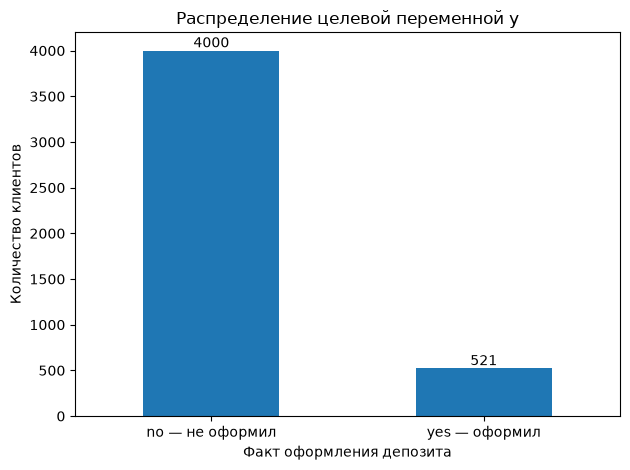

In [119]:

import matplotlib.pyplot as plt

# Подсчитываем количество объектов каждого класса
class_counts = df["y"].value_counts().reindex(
    ["no", "yes"], fill_value=0
)

# Рассчитываем долю каждого класса в процентах
class_percentages = (
    df["y"]
    .value_counts(normalize=True)
    .reindex(["no", "yes"], fill_value=0)
    * 100
)

# Формируем итоговую таблицу
class_summary = pd.DataFrame({
    "Количество клиентов": class_counts,
    "Доля, %": class_percentages.round(2)
})

display(class_summary)

# Строим диаграмму распределения классов
ax = class_counts.plot(kind="bar")

ax.set_title("Распределение целевой переменной y")
ax.set_xlabel("Факт оформления депозита")
ax.set_ylabel("Количество клиентов")
ax.set_xticklabels(["no — не оформил", "yes — оформил"], rotation=0)

# Подписываем столбцы значениями
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()



#### Вывод по распределению целевой переменной

Анализ целевой переменной `y` (факт оформления срочного банковского депозита) показал, что в датасете присутствует **дисбаланс классов**.

Из 4521 наблюдения в 4000 случаях (88,48%) клиент не оформил депозит, а в 521 случае (11,52%) депозит был оформлен.

Таким образом, отрицательный класс `no` (депозит не оформлен) представлен примерно в 7,68 раза чаще положительного класса `yes` (депозит оформлен).

Данный дисбаланс необходимо учитывать при обучении и оценке классификаторов. Высокое значение Accuracy (доли правильных предсказаний) само по себе не гарантирует, что модель способна обнаруживать клиентов, оформивших депозит.

Поэтому при сравнении моделей наряду с Accuracy будут использоваться Precision (точность положительных предсказаний), Recall (полнота обнаружения положительного класса), F1-score (гармоническое среднее Precision и Recall) и ROC-AUC (площадь под ROC-кривой).

При дальнейшем разбиении данных будет применена стратификация, позволяющая сохранить приблизительное соотношение классов в обучающей и тестовой выборках.



### 2.6. Анализ числовых признаков

Для изучения характеристик числовых переменных рассчитаем основные описательные статистики и построим гистограммы распределения значений.

В анализ включены следующие признаки:

- `age` (возраст клиента);
- `balance` (баланс банковского счёта);
- `day` (день месяца последнего контакта);
- `duration` (продолжительность последнего контакта в секундах);
- `campaign` (количество контактов в текущей кампании);
- `pdays` (количество дней с предыдущего контакта);
- `previous` (количество контактов до текущей кампании).

Для каждого признака будут определены количество наблюдений, среднее значение, стандартное отклонение, минимум, максимум и квартили.

Гистограммы позволят оценить форму распределения, выявить возможную асимметрию и заметить значения, которые существенно отличаются от основной массы наблюдений.

Полученные результаты будут использованы при выборе способов предварительной обработки данных и подготовке моделей классификации.


Количество числовых признаков: 7


,count,mean,std,min,25%,50%,75%,max
age (возраст клиента),4521.0,41.17,10.58,19.0,33.0,39.0,49.0,87.0
balance (баланс банковского счёта),4521.0,1422.66,3009.64,-3313.0,69.0,444.0,1480.0,71188.0
day (день месяца последнего контакта),4521.0,15.92,8.25,1.0,9.0,16.0,21.0,31.0
"duration (продолжительность контакта, сек.)",4521.0,263.96,259.86,4.0,104.0,185.0,329.0,3025.0
campaign (количество контактов в текущей кампании),4521.0,2.79,3.11,1.0,1.0,2.0,3.0,50.0
pdays (дней с предыдущего контакта),4521.0,39.77,100.12,-1.0,-1.0,-1.0,-1.0,871.0
previous (контакты до текущей кампании),4521.0,0.54,1.69,0.0,0.0,0.0,0.0,25.0


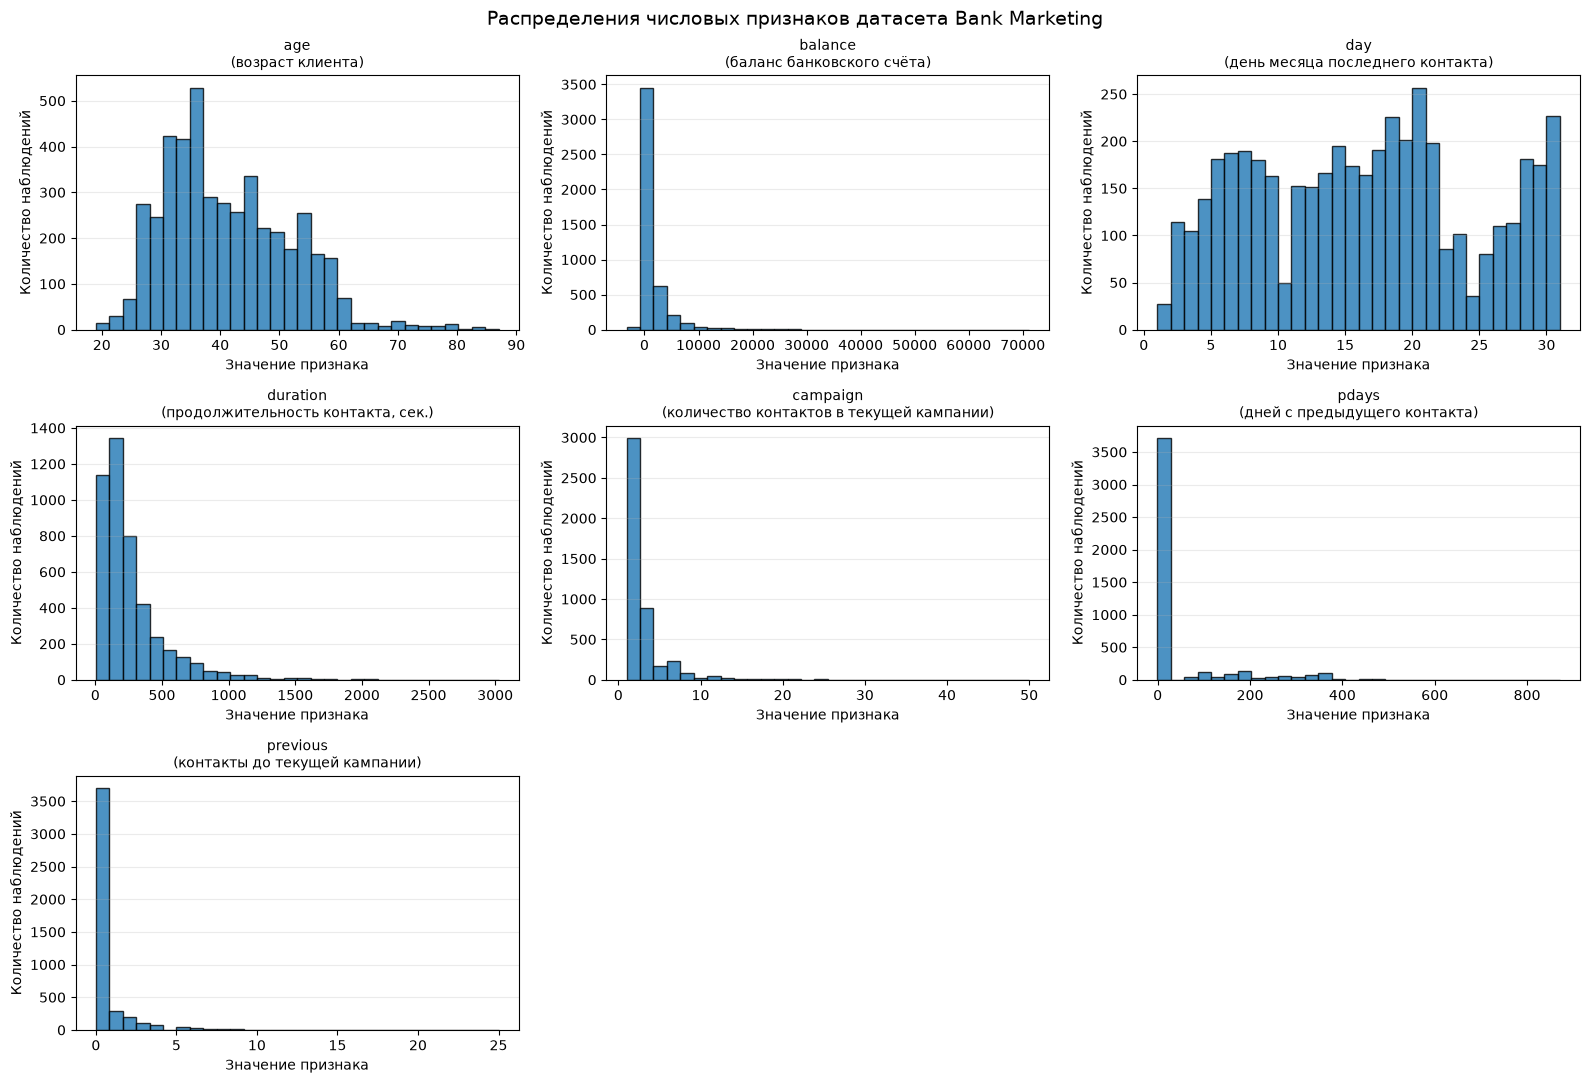

In [120]:

# Названия числовых признаков и их пояснения на русском языке
numeric_descriptions = {
    "age": "возраст клиента",
    "balance": "баланс банковского счёта",
    "day": "день месяца последнего контакта",
    "duration": "продолжительность контакта, сек.",
    "campaign": "количество контактов в текущей кампании",
    "pdays": "дней с предыдущего контакта",
    "previous": "контакты до текущей кампании"
}

# Выбираем числовые столбцы автоматически
numeric_columns = df.select_dtypes(include="number").columns.tolist()

print(f"Количество числовых признаков: {len(numeric_columns)}")

# Рассчитываем описательные статистики
numeric_summary = df[numeric_columns].describe().T.round(2)

# Добавляем пояснения к названиям признаков
numeric_summary.index = [
    f"{column} ({numeric_descriptions[column]})"
    for column in numeric_columns
]

display(numeric_summary)

# Строим гистограммы распределений числовых признаков
fig, axes = plt.subplots(3, 3, figsize=(16, 11))

for ax, column in zip(axes.flat, numeric_columns):
    ax.hist(df[column], bins=30, edgecolor="black", alpha=0.8)
    ax.set_title(
        f"{column}\n({numeric_descriptions[column]})",
        fontsize=10
    )
    ax.set_xlabel("Значение признака")
    ax.set_ylabel("Количество наблюдений")
    ax.grid(axis="y", alpha=0.25)

# Скрываем лишние области графика
for ax in axes.flat[len(numeric_columns):]:
    ax.set_visible(False)

fig.suptitle(
    "Распределения числовых признаков датасета Bank Marketing",
    fontsize=14
)

plt.tight_layout()
plt.show()



#### Вывод по анализу числовых признаков

Анализ описательных статистик и гистограмм показал, что числовые признаки датасета имеют различные диапазоны значений и формы распределений.

Признак `age` (возраст клиента) имеет среднее значение 41,17 года и медиану 39 лет. Признак `balance` (баланс банковского счёта) характеризуется выраженной правосторонней асимметрией: среднее значение составляет 1422,66, тогда как медиана равна 444. Максимальное значение баланса достигает 71188.

Распределение `duration` (продолжительность последнего контакта) также асимметрично вправо: среднее значение составляет 263,96 секунды, медиана — 185 секунд, а максимальное значение — 3025 секунд. Аналогичная особенность наблюдается у `campaign` (количество контактов в текущей кампании).

Для `pdays` (количество дней с предыдущего контакта) характерно большое количество значений −1, обозначающих отсутствие предыдущего контакта. У признака `previous` (количество контактов до текущей кампании) не менее 75% наблюдений имеют нулевое значение.

Полученные результаты показывают, что числовые признаки различаются по масштабу и распределению. Поэтому при подготовке моделей необходимо учитывать особенности каждого алгоритма и применять соответствующее масштабирование там, где оно требуется. Экстремальные значения не будут автоматически удаляться без дополнительного обоснования.

Отдельного внимания требует признак `duration`, поскольку его фактическое значение становится известно только после контакта с клиентом.



### 2.7. Анализ категориальных признаков

Категориальные признаки описывают характеристики клиентов и обстоятельства взаимодействия с банком, выраженные не числовыми измерениями, а отдельными категориями.

В данном датасете рассматриваются следующие признаки:

- `job` (профессия клиента);
- `marital` (семейное положение);
- `education` (уровень образования);
- `default` (наличие кредитного дефолта);
- `housing` (наличие жилищного кредита);
- `loan` (наличие потребительского кредита);
- `contact` (тип связи с клиентом);
- `month` (месяц последнего контакта);
- `poutcome` (результат предыдущей маркетинговой кампании).

Для каждого признака определим количество уникальных категорий и частоту встречаемости отдельных значений. Дополнительно проверим, как часто встречается категория `unknown` (неизвестно).

Результаты анализа помогут определить структуру категориальных данных и подготовить обоснованный подход к их кодированию перед обучением моделей классификации.


,Число уникальных категорий,Количество unknown,"Доля unknown, %"
job (профессия клиента),12,38,0.84
marital (семейное положение),3,0,0.00
education (уровень образования),4,187,4.14
default (наличие кредитного дефолта),2,0,0.00
housing (наличие жилищного кредита),2,0,0.00
loan (наличие потребительского кредита),2,0,0.00
contact (тип связи с клиентом),3,1324,29.29
month (месяц последнего контакта),12,0,0.00
poutcome (результат предыдущей кампании),4,3705,81.95


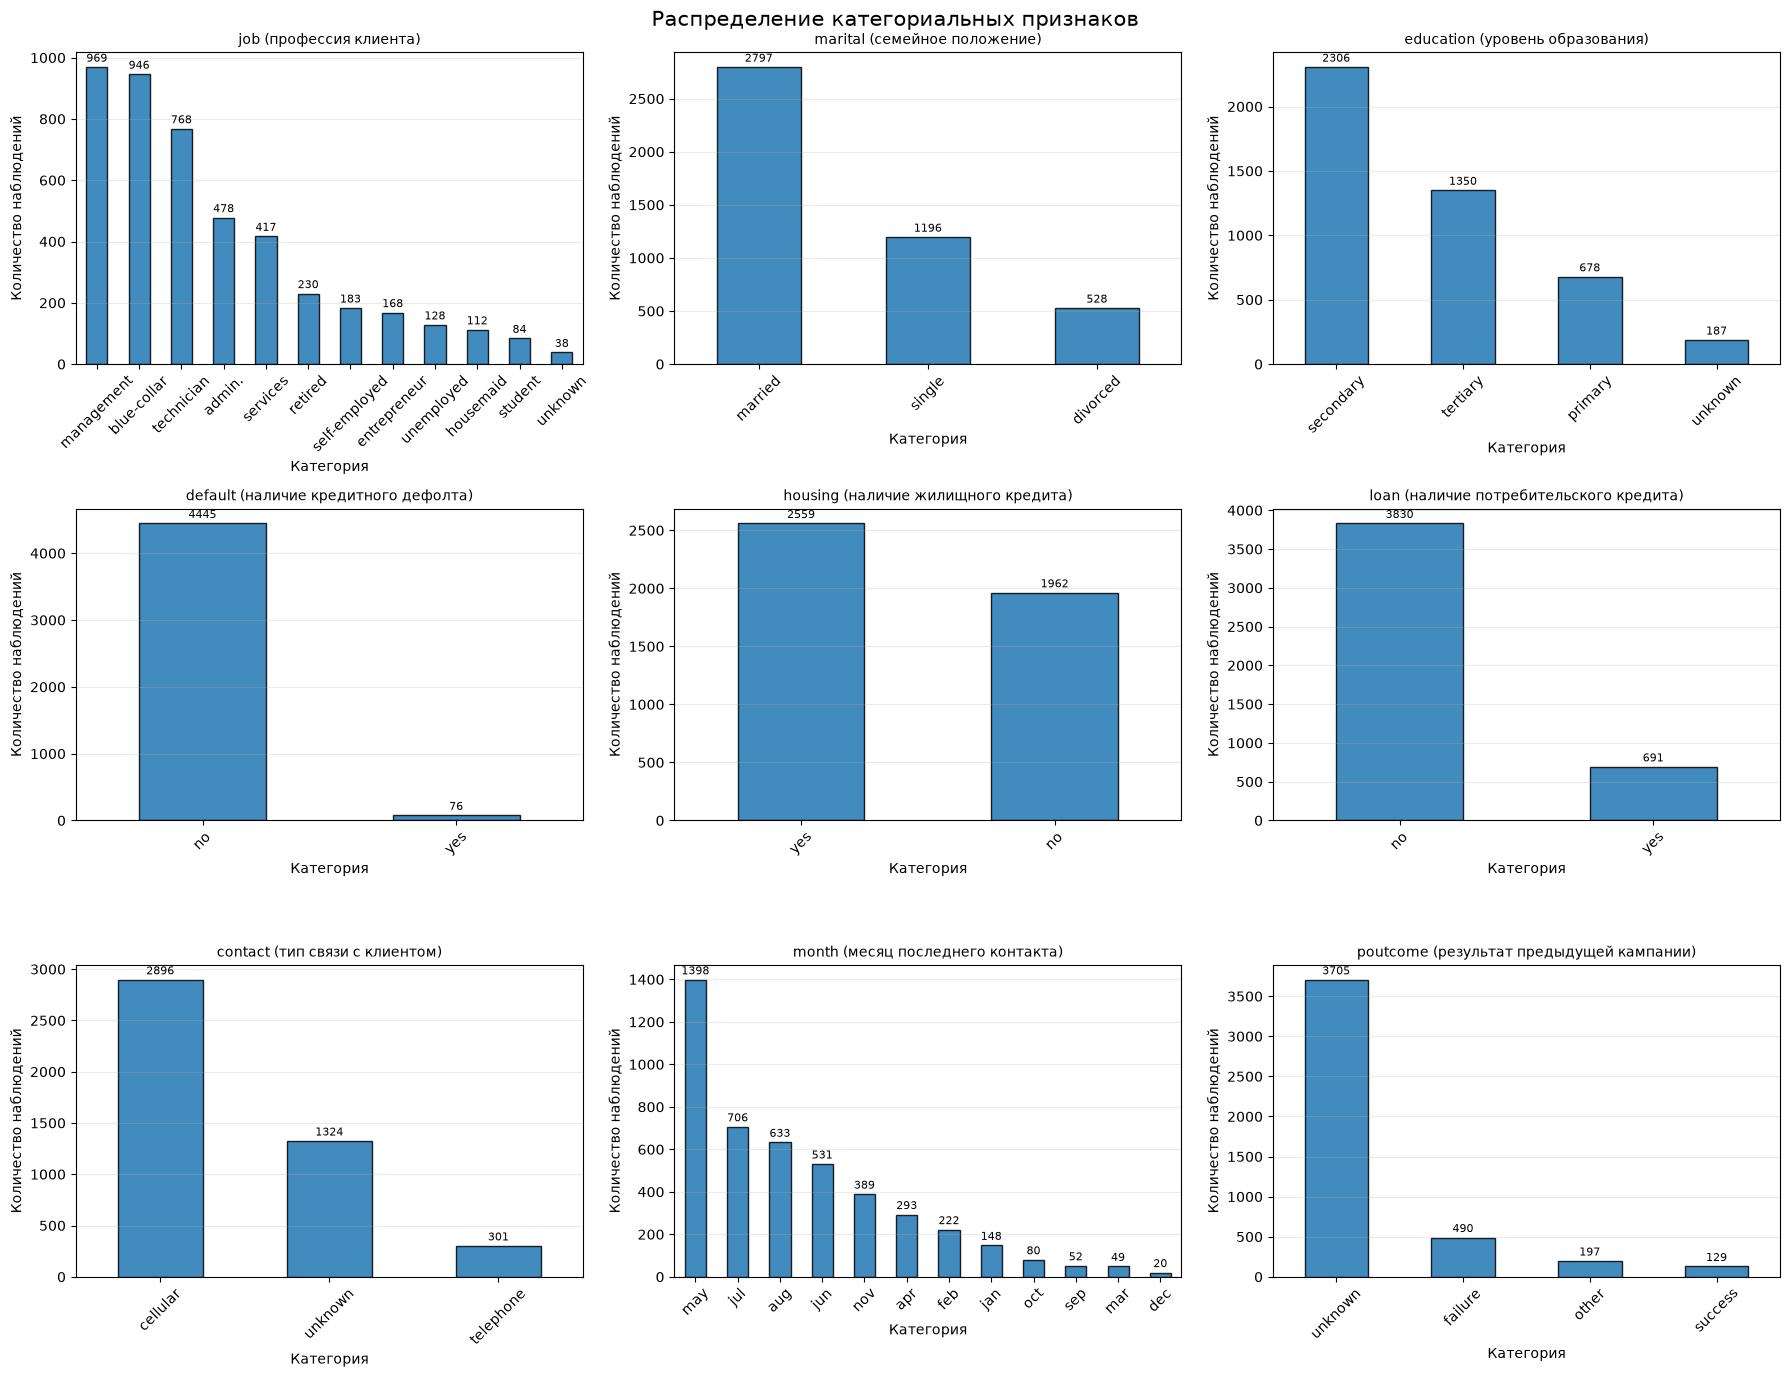

In [121]:

# Названия категориальных признаков и их пояснения
categorical_descriptions = {
    "job": "профессия клиента",
    "marital": "семейное положение",
    "education": "уровень образования",
    "default": "наличие кредитного дефолта",
    "housing": "наличие жилищного кредита",
    "loan": "наличие потребительского кредита",
    "contact": "тип связи с клиентом",
    "month": "месяц последнего контакта",
    "poutcome": "результат предыдущей кампании"
}

categorical_columns = list(categorical_descriptions.keys())

# Формируем сводную таблицу категориальных признаков
categorical_summary = pd.DataFrame(index=categorical_columns)

categorical_summary["Число уникальных категорий"] = [
    df[column].nunique(dropna=False)
    for column in categorical_columns
]

categorical_summary["Количество unknown"] = [
    df[column].astype("string").str.strip().str.lower().eq("unknown").sum()
    for column in categorical_columns
]

categorical_summary["Доля unknown, %"] = (
    categorical_summary["Количество unknown"] / len(df) * 100
).round(2)

categorical_summary.index = [
    f"{column} ({categorical_descriptions[column]})"
    for column in categorical_columns
]

display(categorical_summary)

# Строим диаграммы распределения категорий
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for ax, column in zip(axes.flat, categorical_columns):
    counts = df[column].value_counts(dropna=False)

    counts.plot(
        kind="bar",
        ax=ax,
        edgecolor="black",
        alpha=0.85
    )

    ax.set_title(
        f"{column} ({categorical_descriptions[column]})",
        fontsize=10
    )
    ax.set_xlabel("Категория")
    ax.set_ylabel("Количество наблюдений")
    ax.tick_params(axis="x", labelrotation=45)
    ax.grid(axis="y", alpha=0.25)

    # Подписываем столбцы, если категорий не слишком много
    if len(counts) <= 12:
        for container in ax.containers:
            ax.bar_label(container, fontsize=8, padding=2)

fig.suptitle(
    "Распределение категориальных признаков",
    fontsize=15
)

plt.tight_layout()
plt.show()



#### Вывод по анализу категориальных признаков

Анализ категориальных признаков показал, что датасет содержит разнообразные характеристики клиентов и результаты их взаимодействия с банком. Число уникальных категорий варьируется от двух до двенадцати в зависимости от признака.

Наиболее заметная особенность связана со значением `unknown` (неизвестно). Для признака `poutcome` (результат предыдущей маркетинговой кампании) оно встречается в 3705 наблюдениях (81,95%), а для `contact` (тип связи с клиентом) — в 1324 наблюдениях (29,29%). В признаках `education` (уровень образования) и `job` (профессия клиента) доля таких значений составляет 4,14% и 0,84% соответственно.

Значение `unknown` не является обычным пропуском `NaN`. Поэтому на этапе предварительной обработки эти категории не будут автоматически удаляться. Для представления категориальных переменных в моделях будет применено кодирование, позволяющее сохранить информацию о соответствующих категориях.

Также выявлено неравномерное распределение отдельных значений признаков. Например, большинство клиентов не имеют зарегистрированного кредитного дефолта, а среди известных результатов предыдущей кампании неудачных исходов больше, чем успешных.

Таким образом, категориальные признаки требуют кодирования перед использованием в моделях машинного обучения. При этом необходимо сохранить информацию о категории `unknown` и учитывать особенности распределения значений.



### 2.8. Анализ связи категориальных признаков с целевой переменной

На предыдущем этапе были изучены частоты встречаемости категорий, однако сами по себе эти частоты не показывают, насколько часто клиенты соответствующих групп оформляли срочный депозит.

Для более подробного анализа рассмотрим связь категориальных признаков с целевой переменной `y` (факт оформления депозита).

Для каждой категории рассчитаем:

- количество наблюдений;
- количество клиентов, оформивших депозит;
- долю клиентов, оформивших депозит, в процентах.


Доля успешных исходов рассчитывается по формуле:

$$
P_{\text{yes}} = \frac{N_{\text{yes}}}{N_{\text{category}}} \times 100\%
$$

где:

- $N_{\text{yes}}$ — количество клиентов, оформивших депозит в рассматриваемой категории;
- $N_{\text{category}}$ — общее количество клиентов в этой категории;
- $P_{\text{yes}}$ — доля клиентов, оформивших депозит, в процентах.



Для наглядности построим диаграммы доли оформленных депозитов по категориям каждого признака.

Данный анализ позволит выявить различия между группами клиентов и определить признаки, которые стоит подробнее исследовать при построении классификационных моделей. При этом наблюдаемая связь не означает, что соответствующий признак является причиной оформления депозита.


,Признак,Категория,Всего клиентов,Оформили депозит,"Доля yes, %"
0,job,retired,230,54,23.48
1,job,student,84,19,22.62
2,job,unknown,38,7,18.42
3,job,management,969,131,13.52
4,job,housemaid,112,14,12.50
5,job,admin.,478,58,12.13
6,job,self-employed,183,20,10.93
7,job,technician,768,83,10.81
8,job,unemployed,128,13,10.16
9,job,services,417,38,9.11


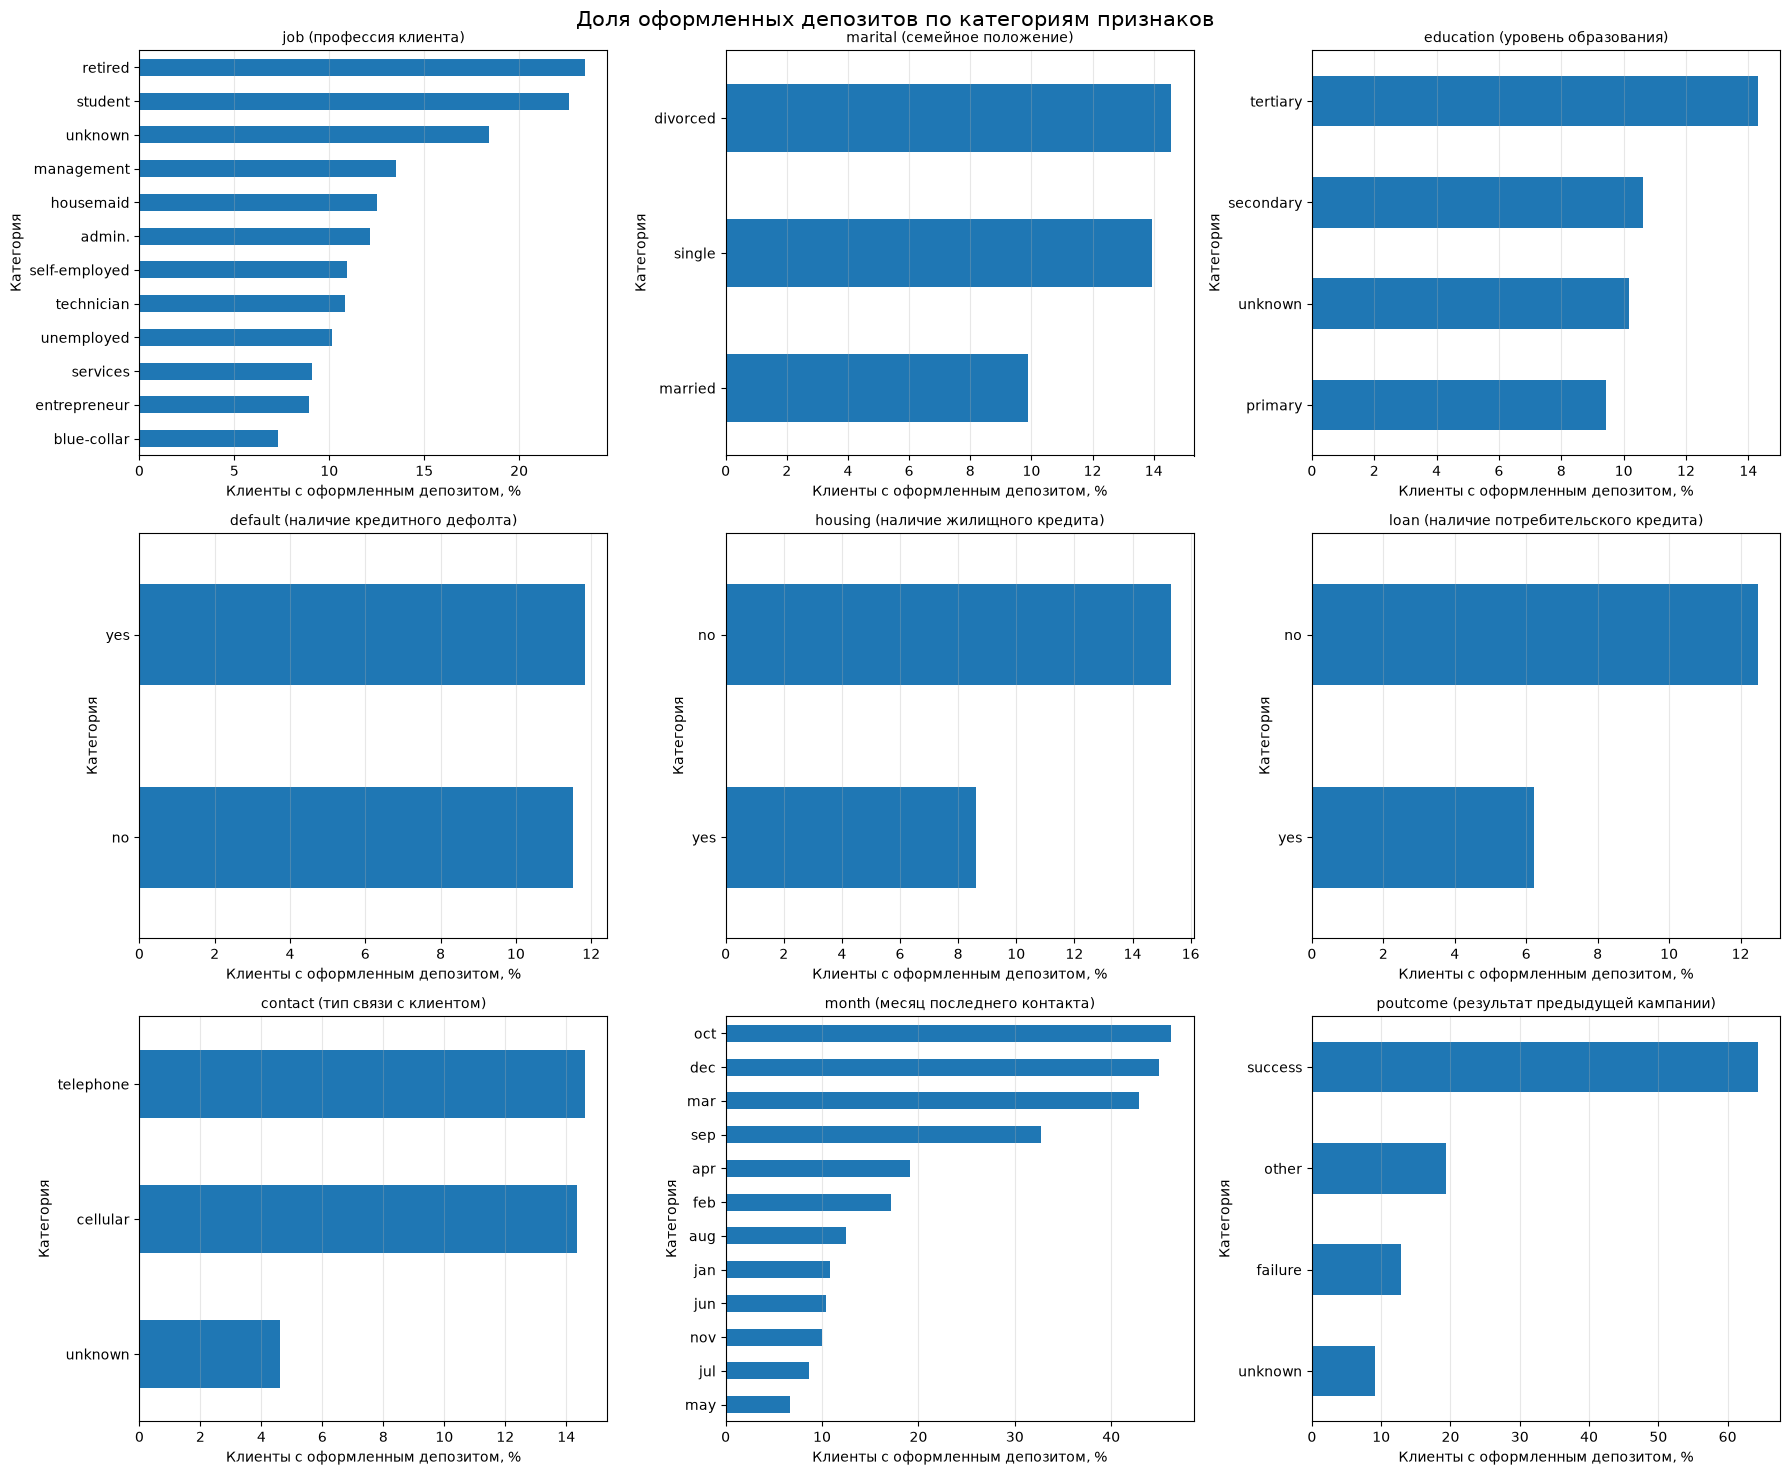

In [122]:

# Рассчитываем количество клиентов и долю оформленных депозитов
# отдельно для каждой категории каждого категориального признака.

target_rate_tables = {}

for column in categorical_columns:
    summary = (
        df.groupby(column, dropna=False)
        .agg(
            total=("y", "size"),
            yes_count=("y", lambda values: values.eq("yes").sum())
        )
    )

    summary["yes_rate_pct"] = (
        summary["yes_count"] / summary["total"] * 100
    ).round(2)

    target_rate_tables[column] = summary.sort_values(
        "yes_rate_pct",
        ascending=False
    )

# Объединяем результаты в одну таблицу
combined_target_rates = (
    pd.concat(
        target_rate_tables,
        names=["Признак", "Категория"]
    )
    .reset_index()
    .rename(columns={
        "total": "Всего клиентов",
        "yes_count": "Оформили депозит",
        "yes_rate_pct": "Доля yes, %"
    })
)

display(combined_target_rates)

# Строим диаграммы доли оформленных депозитов
fig, axes = plt.subplots(3, 3, figsize=(18, 15))

for ax, column in zip(axes.flat, categorical_columns):
    rates = target_rate_tables[column]["yes_rate_pct"].sort_values()

    rates.plot(kind="barh", ax=ax)

    ax.set_title(
        f"{column} ({categorical_descriptions[column]})",
        fontsize=10
    )
    ax.set_xlabel("Клиенты с оформленным депозитом, %")
    ax.set_ylabel("Категория")
    ax.grid(axis="x", alpha=0.3)

fig.suptitle(
    "Доля оформленных депозитов по категориям признаков",
    fontsize=15
)

plt.tight_layout()
plt.show()



#### Вывод по анализу связи категориальных признаков с целевой переменной

Сравнение долей оформленных депозитов показало, что результат маркетинговой кампании различается между категориями клиентов.

Наиболее заметная связь обнаружена для признака `poutcome` (результат предыдущей маркетинговой кампании). Среди клиентов с категорией `success` (успех) депозит оформили 64,34% наблюдений, то есть 83 из 129 клиентов. Это значительно выше общей доли положительного класса, составляющей 11,52%.

Также наблюдаются различия для признаков `housing` (наличие жилищного кредита) и `loan` (наличие потребительского кредита). Доля оформленных депозитов среди клиентов без жилищного кредита составляет 15,34%, а среди клиентов с ним — 8,60%. Для потребительского кредита соответствующие значения равны 12,48% и 6,22%.

Для признака `job` (профессия клиента) относительно высокие доли оформленных депозитов наблюдаются среди пенсионеров — 23,48% — и студентов — 22,62%. Однако количество наблюдений в отдельных категориях различается, поэтому эти показатели необходимо интерпретировать с учётом размера соответствующих групп.

При анализе признака `month` (месяц последнего контакта) также обнаружены различия между категориями. При этом некоторые месяцы представлены небольшим количеством наблюдений, что снижает устойчивость полученных оценок.

Таким образом, исследование выявило потенциально информативные категориальные признаки. Однако наблюдаемая связь не доказывает причинно-следственную зависимость, а влияние признаков необходимо дополнительно оценивать при построении классификационных моделей.



### 2.9. Анализ числовых признаков в зависимости от целевой переменной

На данном этапе исследуем, как числовые характеристики клиентов различаются в зависимости от факта оформления срочного банковского депозита.

Для этого разделим наблюдения на две группы по целевой переменной `y` (факт оформления депозита): `no` (депозит не оформлен) и `yes` (депозит оформлен).

Для каждой группы рассчитаем среднее значение и медиану числовых признаков. Дополнительно построим диаграммы размаха (boxplot), которые позволяют сравнить медианы, межквартильные интервалы и разброс значений.

В анализ включены `age` (возраст клиента), `balance` (баланс банковского счёта), `day` (день месяца последнего контакта), `duration` (продолжительность контакта), `campaign` (количество контактов в текущей кампании), `pdays` (количество дней с предыдущего контакта) и `previous` (количество контактов до текущей кампании).

Сравнение групп позволит выявить различия в распределениях признаков и определить, какие особенности данных необходимо учитывать при построении классификационных моделей.

Следует учитывать, что обнаруженные различия сами по себе не доказывают причинно-следственную связь и не означают, что отдельный признак гарантирует оформление депозита.


Сравнение числовых признаков между группами клиентов:


no (депозит не оформлен)  \
Признак и статистика Показатель                             
age                  mean                           41.00   
                     median                         39.00   
balance              mean                         1403.21   
                     median                        419.50   
day                  mean                           15.95   
                     median                         16.00   
duration             mean                          226.35   
                     median                        167.00   
campaign             mean                            2.86   
                     median                          2.00   
pdays                mean                           36.01   
                     median                         -1.00   
previous             mean                            0.47   
                     median                          0.00   

                                 yes (депозит оформлен)  
Признак и статистика Показатель                          
age                  mean                         42.49  
                     median                       40.00  
balance              mean                       1571.96  
                     median                      710.00  
day                  mean                         15.66  
                     median                       15.00  
duration             mean                        552.74  
                     median                      442.00  
campaign             mean                          2.27  
                     median                        2.00  
pdays                mean                         68.64  
                     median                       -1.00  
previous             mean                          1.09  
                     median                        0.00

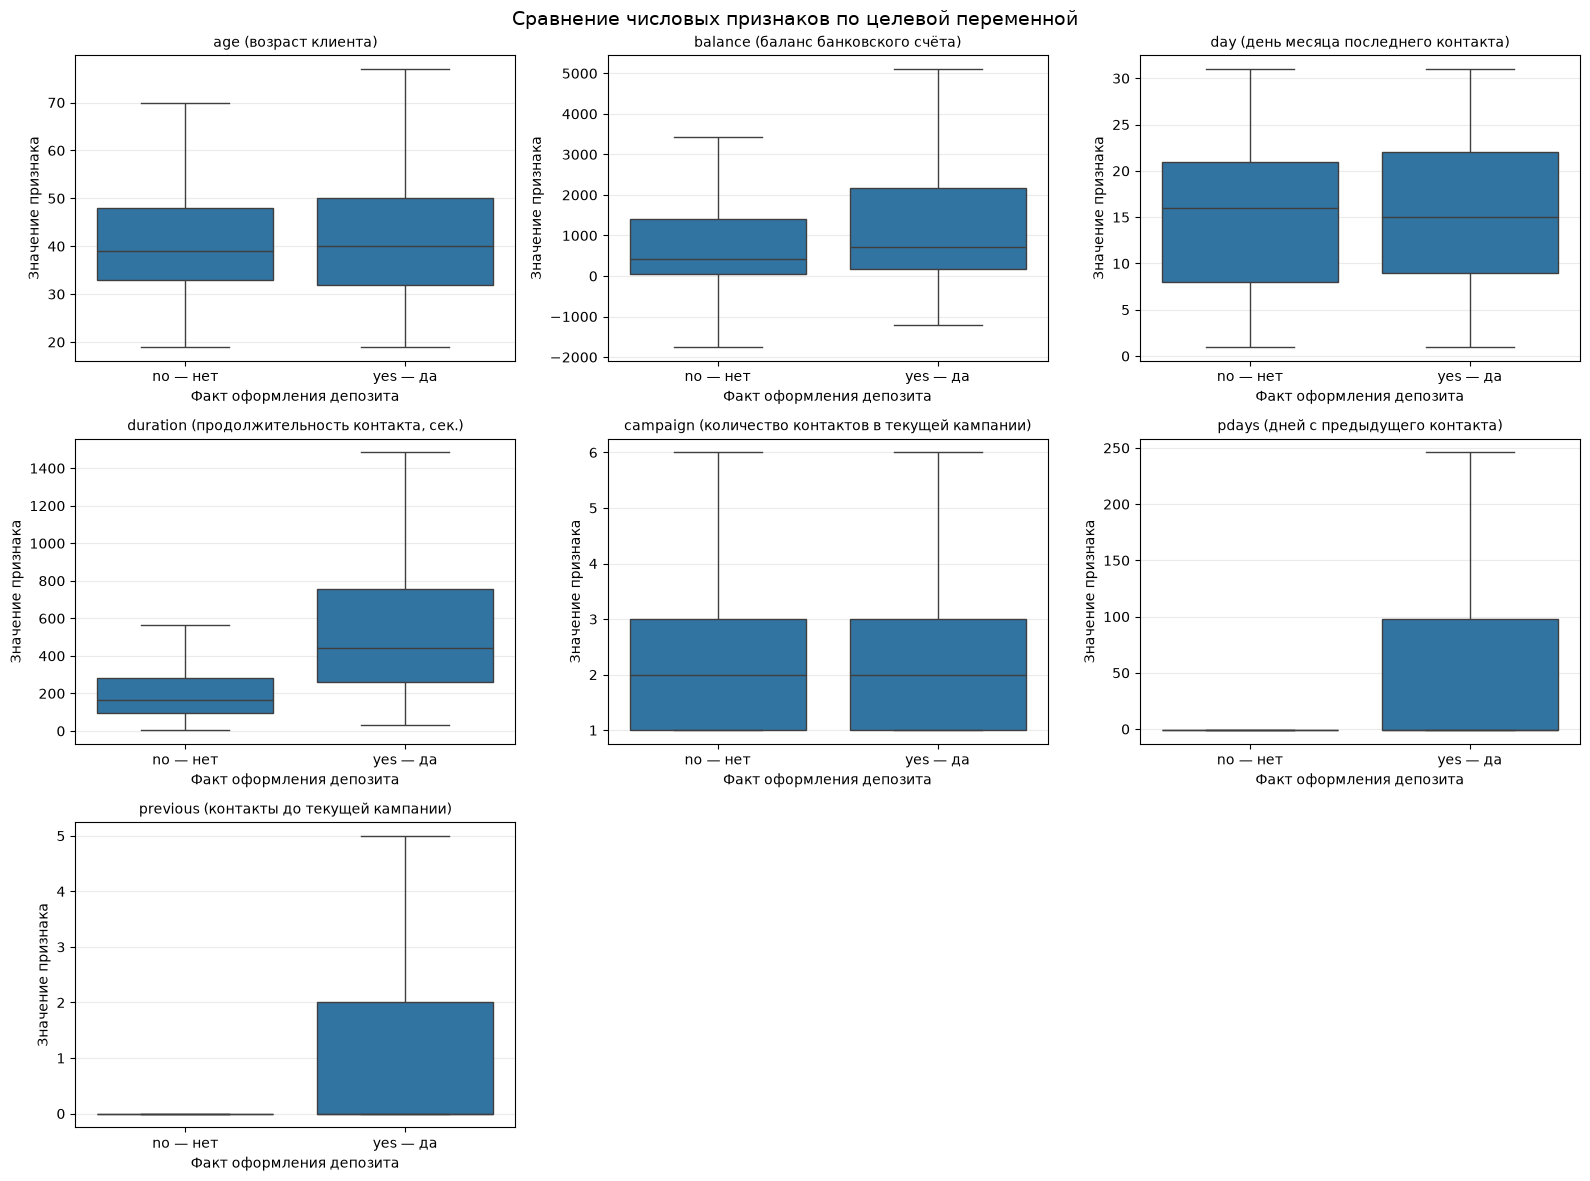

In [123]:

import seaborn as sns

# 1. Сравниваем средние значения и медианы
numeric_target_summary = (
    df.groupby("y")[numeric_columns]
    .agg(["mean", "median"])
    .T
    .round(2)
)

# Делаем названия столбцов понятнее
numeric_target_summary.columns = [
    "no (депозит не оформлен)",
    "yes (депозит оформлен)"
]

numeric_target_summary.index.names = [
    "Признак и статистика",
    "Показатель"
]

print("Сравнение числовых признаков между группами клиентов:")
display(numeric_target_summary)

# 2. Строим диаграммы размаха
fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, column in zip(axes.flat, numeric_columns):
    sns.boxplot(
        data=df,
        x="y",
        y=column,
        order=["no", "yes"],
        showfliers=False,
        ax=ax
    )

    ax.set_title(
        f"{column} ({numeric_descriptions[column]})",
        fontsize=10
    )
    ax.set_xlabel("Факт оформления депозита")
    ax.set_ylabel("Значение признака")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["no — нет", "yes — да"])
    ax.grid(axis="y", alpha=0.25)

# Скрываем лишние области
for ax in axes.flat[len(numeric_columns):]:
    ax.set_visible(False)

fig.suptitle(
    "Сравнение числовых признаков по целевой переменной",
    fontsize=14
)

plt.tight_layout()
plt.show()



#### Вывод по анализу числовых признаков в зависимости от целевой переменной

Сравнение числовых признаков показало, что некоторые характеристики клиентов различаются в зависимости от факта оформления срочного банковского депозита.

Наиболее заметное различие обнаружено для `duration` (продолжительность последнего контакта). Средняя продолжительность контакта у клиентов, не оформивших депозит, составляет 226,35 секунды, а у клиентов, оформивших депозит, — 552,74 секунды. Медианные значения равны 167 и 442 секундам соответственно.

Для `balance` (баланс банковского счёта) медиана составляет 419,50 у клиентов без оформленного депозита и 710,00 у клиентов с оформленным депозитом. Средний возраст клиентов в этих группах составляет 41,00 и 42,49 года соответственно.

Среднее количество контактов в текущей кампании (`campaign`) у клиентов без оформленного депозита составляет 2,86, а у клиентов с оформленным депозитом — 2,27. Для признака `previous` (количество контактов до текущей кампании) наблюдается обратная картина: средние значения равны 0,47 и 1,09 соответственно.

Медиана признака `pdays` (количество дней с предыдущего контакта) в обеих группах равна −1, что связано со специальным обозначением отсутствия предыдущего контакта.

Таким образом, исследование выявило различия в распределениях отдельных числовых признаков между двумя классами. Однако полученные результаты носят описательный характер и не доказывают причинно-следственную зависимость. Дополнительно следует учитывать, что `duration` становится известным только после разговора с клиентом.


### 2.10. Общий вывод по результатам исследования данных

В ходе анализа установлено, что датасет Bank Marketing содержит 4521 наблюдение, 16 входных признаков и целевую переменную `y` (факт оформления срочного депозита). Пропущенных значений и полных дубликатов не обнаружено.

Выявлен дисбаланс классов: 88,48% клиентов не оформили депозит и 11,52% оформили его. Также обнаружены различия в масштабах и распределениях числовых признаков, а в категориальных переменных присутствуют значения `unknown` (неизвестно).

Таким образом, датасет подходит для бинарной классификации. При дальнейшей подготовке необходимо учесть дисбаланс классов, закодировать категориальные признаки, при необходимости масштабировать числовые признаки и сохранить смысл специальных значений. Отдельно следует учитывать, что `duration` (продолжительность контакта) становится известен только после разговора с клиентом.


## 3. Разбиение выборки

Для обучения и оценки классификаторов исходный датасет разделяется на обучающую и тестовую выборки в соотношении 80/20.

Входные признаки обозначаются как `X`, а целевая переменная `y` (факт оформления срочного депозита) — как `y`. Для удобства вычислений целевая переменная кодируется числами: `0` — депозит не оформлен, `1` — депозит оформлен.

При разделении используется стратификация (`stratify`), сохраняющая приблизительное соотношение классов в обеих выборках. Это особенно важно из-за дисбаланса целевой переменной.

Для воспроизводимости экспериментов фиксируется `random_state = 42`. Все последующие преобразования признаков будут настраиваться на обучающей выборке, чтобы избежать утечки информации из тестовой.


In [124]:

from sklearn.model_selection import train_test_split

# Отделяем входные признаки от целевой переменной
X = df.drop(columns="y").copy()
y = df["y"].map({"no": 0, "yes": 1})

# Проверяем корректность кодирования целевой переменной
if y.isna().any():
    raise ValueError("Обнаружены неизвестные значения целевой переменной.")

# Разделяем данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Выводим размеры выборок
print(f"Размер исходной выборки: {len(df)}")
print(f"Обучающая выборка: {X_train.shape[0]} строк")
print(f"Тестовая выборка: {X_test.shape[0]} строк")
print(f"Количество входных признаков: {X_train.shape[1]}")

# Сравниваем распределение классов
split_summary = pd.DataFrame({
    "Обучающая выборка, шт.": (
        y_train.value_counts().reindex([0, 1], fill_value=0)
    ),
    "Обучающая выборка, %": (
        y_train.value_counts(normalize=True)
        .reindex([0, 1], fill_value=0) * 100
    ).round(2),
    "Тестовая выборка, шт.": (
        y_test.value_counts().reindex([0, 1], fill_value=0)
    ),
    "Тестовая выборка, %": (
        y_test.value_counts(normalize=True)
        .reindex([0, 1], fill_value=0) * 100
    ).round(2)
})

split_summary.index = [
    "0 — депозит не оформлен",
    "1 — депозит оформлен"
]

display(split_summary)


Размер исходной выборки: 4521
Обучающая выборка: 3616 строк
Тестовая выборка: 905 строк
Количество входных признаков: 16


,"Обучающая выборка, шт.","Обучающая выборка, %","Тестовая выборка, шт.","Тестовая выборка, %"
0 — депозит не оформлен,3199,88.47,801,88.51
1 — депозит оформлен,417,11.53,104,11.49



### Вывод по разбиению выборки

Исходный датасет разделён на обучающую выборку из 3616 наблюдений (80%) и тестовую выборку из 905 наблюдений (20%). Для сохранения пропорций классов использована стратификация.

Доля клиентов, оформивших депозит, составляет 11,53% в обучающей выборке и 11,49% в тестовой. Таким образом, распределение классов сохранено, а данные подготовлены для обучения и объективной оценки классификаторов.



### 3.1. Определение типов признаков

Перед предобработкой определим тип каждого входного признака.

Числовые признаки при необходимости будут масштабированы, а категориальные — преобразованы с помощью One-Hot Encoding (кодирования категорий отдельными бинарными столбцами).

Это позволит подготовить данные к использованию классификаторов, которые требуют числового представления входных признаков.


In [125]:

# Определяем типы признаков на обучающей выборке
numeric_features = [
    column for column in X_train.columns
    if pd.api.types.is_numeric_dtype(X_train[column])
]

categorical_features = [
    column for column in X_train.columns
    if not pd.api.types.is_numeric_dtype(X_train[column])
]

print(f"Числовых признаков: {len(numeric_features)}")
print(f"Категориальных признаков: {len(categorical_features)}")

# Описания признаков для отчёта
feature_descriptions = {
    "age": "Возраст клиента",
    "job": "Профессия клиента",
    "marital": "Семейное положение",
    "education": "Уровень образования",
    "default": "Наличие кредитного дефолта",
    "balance": "Баланс банковского счёта",
    "housing": "Наличие жилищного кредита",
    "loan": "Наличие потребительского кредита",
    "contact": "Тип связи с клиентом",
    "day": "День месяца последнего контакта",
    "month": "Месяц последнего контакта",
    "duration": "Продолжительность контакта, сек.",
    "campaign": "Количество контактов в текущей кампании",
    "pdays": "Количество дней с предыдущего контакта",
    "previous": "Количество контактов до текущей кампании",
    "poutcome": "Результат предыдущей кампании"
}

feature_types = pd.DataFrame({
    "Тип данных": [
        "Числовой" if column in numeric_features
        else "Категориальный"
        for column in X_train.columns
    ],
    "Описание": [
        feature_descriptions[column]
        for column in X_train.columns
    ]
}, index=X_train.columns)

feature_types.index.name = "Признак"
display(feature_types)

# Проверяем полноту классификации признаков
assert len(numeric_features) == 7
assert len(categorical_features) == 9
assert len(numeric_features) + len(categorical_features) == X_train.shape[1]

print("Проверка пройдена: все 16 признаков классифицированы.")


Числовых признаков: 7
Категориальных признаков: 9


,Тип данных,Описание
Признак,,
age,Числовой,Возраст клиента
job,Категориальный,Профессия клиента
marital,Категориальный,Семейное положение
education,Категориальный,Уровень образования
default,Категориальный,Наличие кредитного дефолта
balance,Числовой,Баланс банковского счёта
housing,Категориальный,Наличие жилищного кредита
loan,Категориальный,Наличие потребительского кредита
contact,Категориальный,Тип связи с клиентом


Проверка пройдена: все 16 признаков классифицированы.



### 3.2. Подготовка преобразований признаков

Для обработки данных используются два преобразователя.

**Первый преобразователь** применяет StandardScaler (стандартизацию числовых признаков) и One-Hot Encoding (кодирование категориальных признаков отдельными бинарными столбцами). Он предназначен для моделей, чувствительных к масштабу признаков.

**Второй преобразователь** применяет MinMaxScaler (масштабирование числовых признаков в диапазон от 0 до 1) и такое же кодирование категорий. Он предназначен для вариантов наивного Байеса, которым необходимы неотрицательные значения.

Для категориальных признаков используется параметр `handle_unknown="ignore"`, позволяющий обрабатывать категории, не встречавшиеся при настройке кодировщика.

Преобразования будут настраиваться на обучающих данных. При последующей оценке моделей они будут включаться в `Pipeline`, чтобы избежать утечки информации при кросс-валидации.


In [126]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.base import clone

# Вариант 1: стандартизация числовых признаков
# и One-Hot Encoding категориальных признаков
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

# Вариант 2: неотрицательные числовые признаки
# и One-Hot Encoding категориальных признаков
preprocessor_nonnegative = ColumnTransformer(
    transformers=[
        (
            "num",
            MinMaxScaler(feature_range=(0, 1), clip=True),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

# Проверяем преобразования на копиях преобразователей.
# Оба варианта настраиваются только на обучающей выборке.
scaled_check = clone(preprocessor_scaled)
X_train_scaled_check = scaled_check.fit_transform(X_train)
X_test_scaled_check = scaled_check.transform(X_test)

nonnegative_check = clone(preprocessor_nonnegative)
X_train_nonnegative_check = nonnegative_check.fit_transform(X_train)
X_test_nonnegative_check = nonnegative_check.transform(X_test)

print("Стандартизированные данные:")
print("Обучающая выборка:", X_train_scaled_check.shape)
print("Тестовая выборка:", X_test_scaled_check.shape)

print("\nНеотрицательные данные:")
print("Обучающая выборка:", X_train_nonnegative_check.shape)
print("Тестовая выборка:", X_test_nonnegative_check.shape)

print(
    "\nМинимум после MinMaxScaler:",
    round(float(X_train_nonnegative_check.min()), 6)
)
print(
    "Минимум в тестовых данных:",
    round(float(X_test_nonnegative_check.min()), 6)
)


Стандартизированные данные:
Обучающая выборка: (3616, 51)
Тестовая выборка: (905, 51)

Неотрицательные данные:
Обучающая выборка: (3616, 51)
Тестовая выборка: (905, 51)

Минимум после MinMaxScaler: 0.0
Минимум в тестовых данных: 0.0



### 3.3. Подготовка данных для BernoulliNB

Классификатор BernoulliNB (бернуллиевский наивный байесовский классификатор) предназначен для работы с бинарными признаками. Поэтому числовые признаки будут преобразованы в значения `0` и `1`, а категориальные — закодированы методом One-Hot Encoding.


In [127]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Binarizer

# Преобразование числовых признаков в бинарные
numeric_binarizer = Pipeline([
    ("scaler", StandardScaler()),
    ("binarizer", Binarizer(threshold=0.0))
])

# Общая предобработка для BernoulliNB
preprocessor_bernoulli = ColumnTransformer(
    transformers=[
        ("num", numeric_binarizer, numeric_features),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Преобразование для BernoulliNB подготовлено.")


Преобразование для BernoulliNB подготовлено.



## 4. Методы классификации


### 4.1. Наивный байесовский классификатор

Наивный байесовский классификатор использует теорему Байеса и предполагает условную независимость признаков при известном классе. В работе рассматриваются четыре варианта алгоритма: GaussianNB, MultinomialNB, ComplementNB и BernoulliNB, отличающиеся предположениями о данных и требованиями к входным признакам.



In [128]:

from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB,
    ComplementNB,
    BernoulliNB
)
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Четыре модели с подходящей предобработкой
nb_models = {
    "GaussianNB": Pipeline([
        ("preprocessing", preprocessor_scaled),
        ("classifier", GaussianNB())
    ]),
    "MultinomialNB": Pipeline([
        ("preprocessing", preprocessor_nonnegative),
        ("classifier", MultinomialNB())
    ]),
    "ComplementNB": Pipeline([
        ("preprocessing", preprocessor_nonnegative),
        ("classifier", ComplementNB())
    ]),
    "BernoulliNB": Pipeline([
        ("preprocessing", preprocessor_bernoulli),
        ("classifier", BernoulliNB())
    ])
}

# Пять стратифицированных разбиений
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Метрики оценки
scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
    "ROC-AUC": "roc_auc"
}

# Оцениваем базовые модели на обучающих данных
baseline_results = []

for name, model in nb_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    row = {"Модель": name}

    for metric in scoring:
        row[metric] = round(scores[f"test_{metric}"].mean(), 4)

    baseline_results.append(row)

baseline_nb_df = pd.DataFrame(baseline_results).set_index("Модель")

display(baseline_nb_df)


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
GaussianNB,0.8435,0.3597,0.4557,0.4013,0.7874
MultinomialNB,0.8874,0.5342,0.2542,0.3434,0.7431
ComplementNB,0.6809,0.2099,0.6430,0.3162,0.7431
BernoulliNB,0.8471,0.3546,0.3959,0.3739,0.7903



#### Вывод по базовым моделям Naive Bayes

Среди четырёх вариантов наивного байесовского классификатора GaussianNB показал наибольший F1-score (0,4013), а BernoulliNB — наибольший ROC-AUC (0,7903). MultinomialNB продемонстрировал максимальную Accuracy (0,8874), однако его Recall составил 0,2542. ComplementNB обеспечил наибольший Recall (0,6430), но имел низкий Precision (0,2099).

Таким образом, универсального лидера по всем метрикам нет. Результаты подтверждают необходимость комплексной оценки моделей с учётом дисбаланса классов.



### 4.2. Дерево решений (Decision Tree)

Дерево решений — алгоритм классификации, который последовательно разделяет данные по значениям признаков. В результате формируется структура из узлов с условиями и конечных узлов (листьев), определяющих предсказываемый класс.

Преимущество метода — возможность моделировать нелинейные зависимости и интерпретировать правила классификации. Основной недостаток — риск переобучения при чрезмерной глубине дерева.

Для базового эксперимента используем стандартные параметры модели и оценим качество с помощью стратифицированной пятиблочной кросс-валидации.


In [129]:

from sklearn.tree import DecisionTreeClassifier

# Для дерева решений масштабирование числовых признаков не требуется
preprocessor_tree = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

# Создаём базовую модель
tree_model = Pipeline([
    ("preprocessing", preprocessor_tree),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Оцениваем модель на тех же пяти блоках
tree_scores = cross_validate(
    tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Выводим средние значения метрик
tree_results = pd.DataFrame(
    [{
        metric: round(tree_scores[f"test_{metric}"].mean(), 4)
        for metric in scoring
    }],
    index=["Decision Tree"]
)

display(tree_results)


,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree,0.8703,0.4447,0.4699,0.4552,0.6962



#### Вывод по модели Decision Tree

Базовая модель дерева решений показала Accuracy = 0,8703, Precision = 0,4447, Recall = 0,4699, F1-score = 0,4552 и ROC-AUC = 0,6962.

Среди рассмотренных базовых моделей дерево решений продемонстрировало наибольший F1-score. Однако значение ROC-AUC оказалось ниже, чем у всех четырёх вариантов наивного Байеса. Следовательно, эффективность модели зависит от выбранной метрики, а окончательный выбор потребует дальнейшего сравнения и настройки гиперпараметров.



### 4.3. Линейный дискриминантный анализ (LDA)

Линейный дискриминантный анализ — метод классификации, который использует статистические характеристики классов для построения линейной границы между ними.

Метод предполагает нормальное распределение признаков внутри классов и общую ковариационную матрицу классов. Для базового эксперимента применим стандартизацию числовых признаков и One-Hot Encoding категориальных признаков.


In [130]:

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Создаём базовую модель LDA
lda_model = Pipeline([
    ("preprocessing", preprocessor_scaled),
    ("classifier", LinearDiscriminantAnalysis())
])

# Оцениваем модель на пяти стратифицированных блоках
lda_scores = cross_validate(
    lda_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Формируем таблицу результатов
lda_results = pd.DataFrame(
    [{
        metric: round(lda_scores[f"test_{metric}"].mean(), 4)
        for metric in scoring
    }],
    index=["LDA"]
)

display(lda_results)


,Accuracy,Precision,Recall,F1,ROC-AUC
LDA,0.901,0.6012,0.4364,0.5048,0.8953



#### Вывод по модели LDA

Базовая модель линейного дискриминантного анализа показала Accuracy = 0,9010, Precision = 0,6012, Recall = 0,4364, F1-score = 0,5048 и ROC-AUC = 0,8953.

Среди рассмотренных базовых моделей LDA продемонстрировала наибольшие значения Accuracy, Precision, F1-score и ROC-AUC. При этом Recall оказался ниже, чем у ComplementNB. Следовательно, эффективность модели зависит от выбранной метрики, а окончательный выбор будет сделан после сравнения остальных алгоритмов и настройки гиперпараметров.



### 4.4. Метод опорных векторов (SVM)

Метод опорных векторов (Support Vector Machine, SVM) строит границу, разделяющую объекты разных классов. При использовании нелинейного ядра алгоритм может моделировать более сложные зависимости между признаками.

SVM чувствителен к масштабу входных данных, поэтому перед обучением числовые признаки стандартизируются, а категориальные преобразуются методом One-Hot Encoding.

В базовом эксперименте будет использовано радиальное базисное ядро (RBF). Влияние параметров регуляризации и ядра исследуем позднее при настройке гиперпараметров.


In [131]:

from sklearn.svm import SVC

# Создаём базовую модель SVM
svm_model = Pipeline([
    ("preprocessing", preprocessor_scaled),
    ("classifier", SVC(kernel="rbf"))
])

# Оцениваем модель на пяти стратифицированных блоках
svm_scores = cross_validate(
    svm_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Формируем таблицу результатов
svm_results = pd.DataFrame(
    [{
        metric: round(svm_scores[f"test_{metric}"].mean(), 4)
        for metric in scoring
    }],
    index=["SVM"]
)

display(svm_results)


,Accuracy,Precision,Recall,F1,ROC-AUC
SVM,0.9004,0.6715,0.2569,0.3674,0.8802



#### Вывод по модели SVM

Базовая модель SVM показала Accuracy = 0,9004, Precision = 0,6715, Recall = 0,2569, F1-score = 0,3674 и ROC-AUC = 0,8802.

Модель продемонстрировала высокую Precision, однако Recall оказался низким: классификатор обнаруживает только 25,69% клиентов, оформивших депозит. По F1-score результат уступает базовым моделям LDA и Decision Tree. Настройка гиперпараметров позволит проверить, можно ли улучшить баланс между Precision и Recall.



### 4.5. Метод ближайших соседей (KNN)

Метод k ближайших соседей (k-Nearest Neighbors, KNN) классифицирует объект на основании классов ближайших к нему объектов обучающей выборки.

Результат зависит от числа соседей \(k\) и выбранной метрики расстояния. Поскольку алгоритм чувствителен к масштабу признаков, числовые переменные стандартизируются, а категориальные кодируются методом One-Hot Encoding.

В базовом эксперименте используется стандартное значение \(k=5\). Влияние числа соседей и других параметров будет исследовано при настройке гиперпараметров.


In [132]:

from sklearn.neighbors import KNeighborsClassifier

# Создаём базовую модель KNN
knn_model = Pipeline([
    ("preprocessing", preprocessor_scaled),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Оцениваем модель на пяти стратифицированных блоках
knn_scores = cross_validate(
    knn_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Формируем таблицу результатов
knn_results = pd.DataFrame(
    [{
        metric: round(knn_scores[f"test_{metric}"].mean(), 4)
        for metric in scoring
    }],
    index=["KNN"]
)

display(knn_results)


,Accuracy,Precision,Recall,F1,ROC-AUC
KNN,0.8988,0.6425,0.2735,0.3829,0.783



#### Вывод по модели KNN

Базовая модель KNN показала Accuracy = 0,8988, Precision = 0,6425, Recall = 0,2735, F1-score = 0,3829 и ROC-AUC = 0,783.

Модель продемонстрировала высокую Precision, однако Recall оказался низким. По F1-score она уступает базовым моделям LDA и Decision Tree. В дальнейшем проверим, позволит ли настройка числа соседей и других гиперпараметров улучшить качество классификации.



### 4.6. Сравнение базовых моделей классификации

Для предварительного сравнения объединим результаты восьми классических моделей, полученные с помощью стратифицированной пятиблочной кросс-валидации.

Все модели оцениваются по одинаковым метрикам: Accuracy, Precision, Recall, F1-score и ROC-AUC. Это позволяет сравнить их результаты до настройки гиперпараметров.


In [133]:

# Объединяем результаты всех базовых классических моделей
baseline_all_df = pd.concat([
    baseline_nb_df,
    tree_results,
    lda_results,
    svm_results,
    knn_results
])

# Сортируем модели по F1-score от лучшей к худшей
baseline_all_df = baseline_all_df.sort_values(
    by="F1",
    ascending=False
)

display(baseline_all_df.style.format("{:.4f}"))


,Accuracy,Precision,Recall,F1,ROC-AUC
LDA,0.9010,0.6012,0.4364,0.5048,0.8953
Decision Tree,0.8703,0.4447,0.4699,0.4552,0.6962
GaussianNB,0.8435,0.3597,0.4557,0.4013,0.7874
KNN,0.8988,0.6425,0.2735,0.3829,0.7830
BernoulliNB,0.8471,0.3546,0.3959,0.3739,0.7903
SVM,0.9004,0.6715,0.2569,0.3674,0.8802
MultinomialNB,0.8874,0.5342,0.2542,0.3434,0.7431
ComplementNB,0.6809,0.2099,0.6430,0.3162,0.7431



#### Вывод по сравнению базовых моделей

По результатам пятиблочной кросс-валидации наилучшие значения F1-score (0,5048) и ROC-AUC (0,8953) показала модель LDA. Второе место по F1-score заняло дерево решений (0,4552).

SVM продемонстрировал наибольшую Precision (0,6715), а ComplementNB — наибольшую Recall (0,6430). Это показывает, что модели по-разному балансируют точность положительных предсказаний и полноту обнаружения клиентов, оформивших депозит.

Полученные результаты являются базовыми. Для окончательного сравнения необходимо исследовать влияние гиперпараметров всех рассмотренных методов и оценить улучшение качества относительно исходных моделей.



## 5. Настройка гиперпараметров

### 5.1. Настройка наивных байесовских классификаторов

Для исследования влияния гиперпараметров проведём поиск лучших параметров четырёх вариантов Naive Bayes с помощью GridSearchCV (поиска по заданной сетке параметров с кросс-валидацией).

Качество моделей будет оцениваться по пяти метрикам. Основным критерием выбора параметров станет F1-score, позволяющий учитывать одновременно Precision и Recall.

Результаты настроенных моделей сравним с базовыми значениями, полученными на предыдущем этапе. Тестовую выборку не используем при подборе параметров.


In [134]:

from sklearn.model_selection import GridSearchCV

# Наборы гиперпараметров для четырёх вариантов Naive Bayes
nb_param_grids = {
    "GaussianNB": {
        "classifier__var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5]
    },
    "MultinomialNB": {
        "classifier__alpha": [0.01, 0.1, 0.5, 1.0, 2.0],
        "classifier__fit_prior": [True, False]
    },
    "ComplementNB": {
        "classifier__alpha": [0.01, 0.1, 0.5, 1.0, 2.0],
        "classifier__norm": [False, True]
    },
    "BernoulliNB": {
        "classifier__alpha": [0.01, 0.1, 0.5, 1.0, 2.0],
        "classifier__fit_prior": [True, False]
    }
}

# Подбираем параметры с помощью пятиблочной кросс-валидации
nb_searches = {}

for name, model in nb_models.items():
    search = GridSearchCV(
        estimator=model,
        param_grid=nb_param_grids[name],
        scoring=scoring,
        refit="F1",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_train, y_train)
    nb_searches[name] = search

# Собираем лучшие результаты и сравниваем их с базовыми
nb_tuning_summary = []

for name, search in nb_searches.items():
    best_index = search.best_index_
    row = {
        "Модель": name,
        "Лучшие параметры": search.best_params_,
        "F1 до настройки": baseline_nb_df.loc[name, "F1"]
    }

    for metric in scoring:
        row[metric] = round(
            search.cv_results_[f"mean_test_{metric}"][best_index],
            4
        )

    row["Изменение F1"] = round(
        row["F1"] - row["F1 до настройки"],
        4
    )

    nb_tuning_summary.append(row)

nb_tuning_summary_df = (
    pd.DataFrame(nb_tuning_summary)
    .set_index("Модель")
)

display(nb_tuning_summary_df)


best_params_table = pd.DataFrame([
    {
        "Модель": name,
        "Оптимальные параметры": "; ".join(
            f"{param.replace('classifier__', '')} = {value}"
            for param, value in search.best_params_.items()
        )
    }
    for name, search in nb_searches.items()
]).set_index("Модель")

display(
    best_params_table.style
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [("text-align", "left")]
        }
    ])
)

# Анализ влияния значений гиперпараметров на средний F1
nb_parameter_effect = []

for model_name, search in nb_searches.items():
    results = pd.DataFrame(search.cv_results_)

    for parameter in search.param_grid:
        values = results[f"param_{parameter}"].astype(object)
        values = values.where(values.notna(), "None")

        grouped = pd.DataFrame({
            "Значение": values.astype(str),
            "F1": results["mean_test_F1"]
        }).groupby("Значение", sort=False)["F1"].mean()

        for value, mean_f1 in grouped.items():
            nb_parameter_effect.append({
                "Модель": model_name,
                "Параметр": parameter.replace("classifier__", ""),
                "Значение": value,
                "Средний F1 по сетке": round(float(mean_f1), 4)
            })

nb_parameter_effect_df = pd.DataFrame(nb_parameter_effect)

display(
    nb_parameter_effect_df.style.format({
        "Средний F1 по сетке": "{:.4f}"
    })
)



,Лучшие параметры,F1 до настройки,Accuracy,Precision,Recall,F1,ROC-AUC,Изменение F1
Модель,,,,,,,,
GaussianNB,{'classifier__var_smoothing': 1e-05},0.4013,0.8438,0.3608,0.4581,0.4029,0.7874,0.0016
MultinomialNB,"{'classifier__alpha': 0.5, 'classifier__fit_pr...",0.3434,0.8880,0.5404,0.2566,0.3467,0.7430,0.0033
ComplementNB,"{'classifier__alpha': 0.01, 'classifier__norm'...",0.3162,0.8850,0.5072,0.2711,0.3524,0.7384,0.0362
BernoulliNB,"{'classifier__alpha': 0.01, 'classifier__fit_p...",0.3739,0.8479,0.3598,0.4055,0.3810,0.7903,0.0071


,Оптимальные параметры
Модель,
GaussianNB,var_smoothing = 1e-05
MultinomialNB,alpha = 0.5; fit_prior = True
ComplementNB,alpha = 0.01; norm = True
BernoulliNB,alpha = 0.01; fit_prior = True


,Модель,Параметр,Значение,Средний F1 по сетке
0,GaussianNB,var_smoothing,1e-11,0.4013
1,GaussianNB,var_smoothing,1e-09,0.4013
2,GaussianNB,var_smoothing,1e-07,0.4013
3,GaussianNB,var_smoothing,1e-05,0.4029
4,MultinomialNB,alpha,0.01,0.3312
5,MultinomialNB,alpha,0.1,0.3312
6,MultinomialNB,alpha,0.5,0.3326
7,MultinomialNB,alpha,1.0,0.3298
8,MultinomialNB,alpha,2.0,0.3284
9,MultinomialNB,fit_prior,True,0.3429



#### Вывод по настройке Naive Bayes

Исследование гиперпараметров показало, что их влияние зависит от варианта наивного байесовского классификатора. Для GaussianNB лучший результат получен при `var_smoothing = 1e-5`. Для MultinomialNB более высокое среднее значение F1 показал вариант `fit_prior = True`, а для ComplementNB — `norm = True`. У BernoulliNB изменение `alpha` оказало незначительное влияние на средний F1.

После настройки наибольший F1-score среди четырёх вариантов Naive Bayes показал GaussianNB (0,4029). Наибольший прирост относительно базовой модели получил ComplementNB: F1 увеличился с 0,3162 до 0,3524.



### 5.2. Настройка гиперпараметров дерева решений

Для исследования влияния сложности дерева на качество классификации используем GridSearchCV (поиск по сетке параметров с кросс-валидацией).

Будем изменять максимальную глубину дерева (`max_depth`), минимальное количество объектов для разделения узла (`min_samples_split`), минимальное количество объектов в листе (`min_samples_leaf`), критерий разделения (`criterion`) и способ учёта дисбаланса классов (`class_weight`).

Основным критерием выбора параметров станет F1-score. Результаты настроенной модели сравним с базовым экспериментом.


In [135]:

# Сетка гиперпараметров дерева решений
tree_param_grid = {
    "classifier__max_depth": [None, 5, 10, 15, 20],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10],
    "classifier__criterion": ["gini", "entropy"],
    "classifier__class_weight": [None, "balanced"]
}

# Поиск лучших параметров по F1-score
tree_search = GridSearchCV(
    estimator=tree_model,
    param_grid=tree_param_grid,
    scoring=scoring,
    refit="F1",
    cv=cv,
    n_jobs=-1
)

tree_search.fit(X_train, y_train)

# Результаты лучшей комбинации параметров
best_index = tree_search.best_index_

tree_tuning_result = pd.DataFrame([{
    metric: round(
        tree_search.cv_results_[f"mean_test_{metric}"][best_index], 4
    )
    for metric in scoring
}])

tree_tuning_result.insert(
    0, "F1 до настройки", tree_results.loc["Decision Tree", "F1"]
)

tree_tuning_result["Изменение F1"] = (
    tree_tuning_result["F1"] - tree_tuning_result["F1 до настройки"]
).round(4)

display(tree_tuning_result)

# Красиво выводим лучшие параметры
tree_best_params = pd.DataFrame({
    "Параметр": [
        name.replace("classifier__", "")
        for name in tree_search.best_params_
    ],
    "Лучшее значение": [
        str(value)
        for value in tree_search.best_params_.values()
    ]
})

display(tree_best_params)


# Средний F1 при разных значениях каждого параметра
cv_results_tree = pd.DataFrame(tree_search.cv_results_)

parameter_names = {
    "classifier__max_depth": "Максимальная глубина",
    "classifier__min_samples_split": "Минимум для разделения",
    "classifier__min_samples_leaf": "Минимум в листе",
    "classifier__criterion": "Критерий разделения",
    "classifier__class_weight": "Учёт дисбаланса классов"
}

effect_rows = []

for parameter, description in parameter_names.items():
    values = cv_results_tree[f"param_{parameter}"].astype(object)
    values = values.where(values.notna(), "None")

    effect_data = pd.DataFrame({
        "Значение": values.astype(str),
        "F1": cv_results_tree["mean_test_F1"]
    })

    grouped = effect_data.groupby(
        "Значение", sort=False
    )["F1"].mean()

    for value, mean_f1 in grouped.items():
        effect_rows.append({
            "Параметр": description,
            "Значение": value,
            "Средний F1 по сетке": round(float(mean_f1), 4)
        })

tree_parameter_effect = pd.DataFrame(effect_rows)
display(tree_parameter_effect)


,F1 до настройки,Accuracy,Precision,Recall,F1,ROC-AUC,Изменение F1
0,0.4552,0.893,0.5453,0.4389,0.4858,0.804,0.0306


,Параметр,Лучшее значение
0,class_weight,None
1,criterion,entropy
2,max_depth,20
3,min_samples_leaf,5
4,min_samples_split,20


,Параметр,Значение,Средний F1 по сетке
0,Максимальная глубина,None,0.4476
1,Максимальная глубина,5,0.4450
2,Максимальная глубина,10,0.4470
3,Максимальная глубина,15,0.4454
4,Максимальная глубина,20,0.4479
5,Минимум для разделения,2,0.4441
6,Минимум для разделения,10,0.4458
7,Минимум для разделения,20,0.4499
8,Минимум в листе,1,0.4422
9,Минимум в листе,5,0.4519



#### Вывод по настройке Decision Tree

После настройки гиперпараметров F1-score дерева решений увеличился с 0,4552 до 0,4858, а ROC-AUC — с 0,6962 до 0,8040. Наилучший результат получен при глубине дерева 20, минимальном размере листа 5 и минимуме 20 объектов для разделения узла.

Таким образом, настройка улучшила качество модели, особенно по ROC-AUC. При этом Precision увеличилась, а Recall немного снизилась, что отражает компромисс между точностью и полнотой классификации.



### 5.3. Настройка гиперпараметров LDA

Для улучшения качества линейного дискриминантного анализа исследуем параметр `solver` (алгоритм решения) и `shrinkage` (регуляризация ковариационной матрицы).

Подбор параметров выполним с помощью GridSearchCV и пятиблочной стратифицированной кросс-валидации. Основным критерием выбора модели станет F1-score. Результаты сравним с базовой моделью LDA.


In [136]:

# Сетка параметров LDA.
# Shrinkage применяется только с solver="lsqr" или solver="eigen".
lda_param_grid = [
    {"classifier__solver": ["svd"]},
    {
        "classifier__solver": ["lsqr"],
        "classifier__shrinkage": [None, "auto", 0.1, 0.5, 0.9]
    },
    {
        "classifier__solver": ["eigen"],
        "classifier__shrinkage": ["auto", 0.1, 0.5, 0.9]
    }
]

lda_search = GridSearchCV(
    estimator=lda_model,
    param_grid=lda_param_grid,
    scoring=scoring,
    refit="F1",
    cv=cv,
    n_jobs=-1
)

lda_search.fit(X_train, y_train)

# Сравнение базовой и настроенной моделей
best_index = lda_search.best_index_

lda_tuning_result = pd.DataFrame([{
    "F1 до настройки": lda_results.loc["LDA", "F1"],
    **{
        metric: round(
            lda_search.cv_results_[f"mean_test_{metric}"][best_index], 4
        )
        for metric in scoring
    }
}])

lda_tuning_result["Изменение F1"] = (
    lda_tuning_result["F1"]
    - lda_tuning_result["F1 до настройки"]
).round(4)

display(lda_tuning_result)

# Лучшие параметры
lda_best_params = pd.DataFrame([
    {
        "Параметр": key.replace("classifier__", ""),
        "Лучшее значение": str(value)
    }
    for key, value in lda_search.best_params_.items()
])

display(lda_best_params)

# Сравнение всех проверенных комбинаций
lda_grid_results = pd.DataFrame([
    {
        "Параметры": ", ".join(
            f"{key.replace('classifier__', '')}={value}"
            for key, value in params.items()
        ),
        "F1 CV": round(
            lda_search.cv_results_["mean_test_F1"][i], 4
        ),
        "ROC-AUC CV": round(
            lda_search.cv_results_["mean_test_ROC-AUC"][i], 4
        )
    }
    for i, params in enumerate(lda_search.cv_results_["params"])
]).sort_values("F1 CV", ascending=False)

display(lda_grid_results)


,F1 до настройки,Accuracy,Precision,Recall,F1,ROC-AUC,Изменение F1
0,0.5048,0.9063,0.6411,0.4292,0.5134,0.8966,0.0086


,Параметр,Лучшее значение
0,shrinkage,0.1
1,solver,lsqr


,Параметры,F1 CV,ROC-AUC CV
7,"shrinkage=0.1, solver=eigen",0.5134,0.8966
3,"shrinkage=0.1, solver=lsqr",0.5134,0.8966
9,"shrinkage=0.9, solver=eigen",0.5116,0.8673
5,"shrinkage=0.9, solver=lsqr",0.5116,0.8673
1,"shrinkage=None, solver=lsqr",0.5053,0.8944
0,solver=svd,0.5048,0.8953
6,"shrinkage=auto, solver=eigen",0.5004,0.8969
2,"shrinkage=auto, solver=lsqr",0.5004,0.8969
4,"shrinkage=0.5, solver=lsqr",0.4873,0.8816
8,"shrinkage=0.5, solver=eigen",0.4873,0.8816



#### Вывод по настройке LDA

После настройки гиперпараметров F1-score увеличился с 0,5048 до 0,5134, а ROC-AUC — с 0,8953 до 0,8966. Лучшие параметры: `solver = lsqr`, `shrinkage = 0.1`.

Таким образом, регуляризация ковариационной матрицы немного улучшила качество классификации. При этом Precision увеличилась, а Recall незначительно снизилась.



### 5.4. Настройка гиперпараметров SVM

Для настройки метода опорных векторов исследуем параметр регуляризации `C`, тип ядра `kernel`, параметр `gamma` для RBF-ядра и способ учёта дисбаланса классов `class_weight`.

Подбор параметров выполним с помощью GridSearchCV и пятиблочной стратифицированной кросс-валидации. Основным критерием выбора станет F1-score.


In [137]:

# Сетка параметров SVM
svm_param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", "auto"],
        "classifier__class_weight": [None, "balanced"]
    }
]

svm_search = GridSearchCV(
    estimator=svm_model,
    param_grid=svm_param_grid,
    scoring=scoring,
    refit="F1",
    cv=cv,
    n_jobs=-1
)

svm_search.fit(X_train, y_train)

# Сравниваем базовую и настроенную модели
best_index = svm_search.best_index_

svm_tuning_result = pd.DataFrame([{
    "F1 до настройки": svm_results.loc["SVM", "F1"],
    **{
        metric: round(
            svm_search.cv_results_[f"mean_test_{metric}"][best_index], 4
        )
        for metric in scoring
    }
}])

svm_tuning_result["Изменение F1"] = (
    svm_tuning_result["F1"]
    - svm_tuning_result["F1 до настройки"]
).round(4)

display(svm_tuning_result)

# Выводим лучшие параметры
svm_best_params = pd.DataFrame([
    {
        "Параметр": key.replace("classifier__", ""),
        "Лучшее значение": str(value)
    }
    for key, value in svm_search.best_params_.items()
])

display(svm_best_params)

# Сравниваем комбинации параметров
svm_grid_results = pd.DataFrame([
    {
        "Параметры": ", ".join(
            f"{key.replace('classifier__', '')}={value}"
            for key, value in params.items()
        ),
        "F1 CV": round(
            svm_search.cv_results_["mean_test_F1"][i], 4
        ),
        "ROC-AUC CV": round(
            svm_search.cv_results_["mean_test_ROC-AUC"][i], 4
        )
    }
    for i, params in enumerate(svm_search.cv_results_["params"])
]).sort_values("F1 CV", ascending=False)

display(svm_grid_results)


,F1 до настройки,Accuracy,Precision,Recall,F1,ROC-AUC,Изменение F1
0,0.3674,0.849,0.4168,0.7507,0.535,0.897,0.1676


,Параметр,Лучшее значение
0,C,1
1,class_weight,balanced
2,gamma,scale
3,kernel,rbf


,Параметры,F1 CV,ROC-AUC CV
12,"C=1, class_weight=balanced, gamma=scale, kerne...",0.5350,0.8970
17,"C=10, class_weight=balanced, gamma=auto, kerne...",0.5309,0.8916
13,"C=1, class_weight=balanced, gamma=auto, kernel...",0.5183,0.8953
3,"C=1, class_weight=balanced, kernel=linear",0.5119,0.8903
5,"C=10, class_weight=balanced, kernel=linear",0.5113,0.8897
1,"C=0.1, class_weight=balanced, kernel=linear",0.5110,0.8925
9,"C=0.1, class_weight=balanced, gamma=auto, kern...",0.4931,0.8816
8,"C=0.1, class_weight=balanced, gamma=scale, ker...",0.4911,0.8857
14,"C=10, class_weight=None, gamma=scale, kernel=rbf",0.4712,0.8744
16,"C=10, class_weight=balanced, gamma=scale, kern...",0.4687,0.8654



#### Вывод по настройке SVM

После настройки гиперпараметров F1-score увеличился с 0,3674 до 0,5350, а ROC-AUC — с 0,8802 до 0,8970. Лучшие параметры: `C = 1`, `class_weight = balanced`, `gamma = scale`, `kernel = rbf`.

Использование сбалансированных весов классов позволило увеличить Recall с 0,2569 до 0,7507, хотя Precision снизилась с 0,6715 до 0,4168. В результате баланс Precision и Recall улучшился, что привело к росту F1-score.



### 5.5. Настройка гиперпараметров KNN

Для настройки метода ближайших соседей исследуем число соседей `n_neighbors`, способ учёта их голосов `weights` и параметр `p`, определяющий метрику Минковского.

Подбор параметров выполним с помощью GridSearchCV и пятиблочной стратифицированной кросс-валидации. Основным критерием выбора станет F1-score.


In [138]:

# Сетка гиперпараметров KNN
knn_param_grid = {
    "classifier__n_neighbors": [3, 5, 7, 11, 15],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2]
}

knn_search = GridSearchCV(
    estimator=knn_model,
    param_grid=knn_param_grid,
    scoring=scoring,
    refit="F1",
    cv=cv,
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

# Сравнение базовой и настроенной моделей
best_index = knn_search.best_index_

knn_tuning_result = pd.DataFrame([{
    "F1 до настройки": knn_results.loc["KNN", "F1"],
    **{
        metric: round(
            knn_search.cv_results_[f"mean_test_{metric}"][best_index], 4
        )
        for metric in scoring
    }
}])

knn_tuning_result["Изменение F1"] = (
    knn_tuning_result["F1"]
    - knn_tuning_result["F1 до настройки"]
).round(4)

display(knn_tuning_result)

# Таблица лучших параметров
knn_best_params = pd.DataFrame([
    {
        "Параметр": key.replace("classifier__", ""),
        "Лучшее значение": str(value)
    }
    for key, value in knn_search.best_params_.items()
])

display(knn_best_params)

# Анализ влияния каждого параметра на средний F1
knn_cv_results = pd.DataFrame(knn_search.cv_results_)

knn_parameter_names = {
    "classifier__n_neighbors": "Количество соседей",
    "classifier__weights": "Вес соседей",
    "classifier__p": "Параметр метрики расстояния"
}

knn_effect_rows = []

for parameter, description in knn_parameter_names.items():
    grouped = knn_cv_results.groupby(
        f"param_{parameter}",
        observed=True
    )["mean_test_F1"].mean()

    for value, mean_f1 in grouped.items():
        knn_effect_rows.append({
            "Параметр": description,
            "Значение": str(value),
            "Средний F1 по сетке": round(float(mean_f1), 4)
        })

knn_parameter_effect = pd.DataFrame(knn_effect_rows)
display(knn_parameter_effect)


,F1 до настройки,Accuracy,Precision,Recall,F1,ROC-AUC,Изменение F1
0,0.3829,0.8949,0.5859,0.295,0.3915,0.7452,0.0086


,Параметр,Лучшее значение
0,n_neighbors,3
1,p,2
2,weights,distance


,Параметр,Значение,Средний F1 по сетке
0,Количество соседей,3,0.3676
1,Количество соседей,5,0.3378
2,Количество соседей,7,0.2815
3,Количество соседей,11,0.2418
4,Количество соседей,15,0.1926
5,Вес соседей,distance,0.2872
6,Вес соседей,uniform,0.2814
7,Параметр метрики расстояния,1,0.2351
8,Параметр метрики расстояния,2,0.3334



#### Вывод по настройке KNN

После настройки гиперпараметров F1-score увеличился с 0,3829 до 0,3915. Лучшие параметры: `n_neighbors = 3`, `weights = distance`, `p = 2`.

При этом ROC-AUC снизился с 0,7830 до 0,7452, а Precision уменьшилась с 0,6425 до 0,5859. Таким образом, настройка немного улучшила баланс Precision и Recall, но не повысила качество модели по всем метрикам.



### 5.6. Сравнение моделей после настройки гиперпараметров

После настройки гиперпараметров сравним результаты всех классических классификаторов по пяти метрикам: Accuracy, Precision, Recall, F1-score и ROC-AUC.

Дополнительно оценим изменение F1-score относительно базовых моделей. Это позволит определить, какие алгоритмы улучшили качество классификации после настройки.


In [139]:

# Собираем результаты поиска гиперпараметров всех моделей
tuned_searches = {
    **nb_searches,
    "Decision Tree": tree_search,
    "LDA": lda_search,
    "SVM": svm_search,
    "KNN": knn_search
}

tuned_rows = []
best_params_rows = []

for name, search in tuned_searches.items():
    idx = search.best_index_

    row = {
        "Модель": name,
        "F1 до настройки": baseline_all_df.loc[name, "F1"]
    }

    for metric in scoring:
        row[metric] = search.cv_results_[f"mean_test_{metric}"][idx]

    row["Изменение F1"] = row["F1"] - row["F1 до настройки"]
    tuned_rows.append(row)

    best_params_rows.append({
        "Модель": name,
        "Лучшие параметры": "; ".join(
            f"{key.replace('classifier__', '')} = {value}"
            for key, value in search.best_params_.items()
        )
    })

# Итоговая таблица метрик
tuned_comparison = (
    pd.DataFrame(tuned_rows)
    .set_index("Модель")
    .sort_values("F1", ascending=False)
)

display(tuned_comparison.style.format("{:.4f}"))

# Сводная таблица лучших параметров
best_params_comparison = (
    pd.DataFrame(best_params_rows)
    .set_index("Модель")
)

display(best_params_comparison)


,F1 до настройки,Accuracy,Precision,Recall,F1,ROC-AUC,Изменение F1
Модель,,,,,,,
SVM,0.3674,0.8490,0.4168,0.7507,0.5350,0.8970,0.1676
LDA,0.5048,0.9063,0.6411,0.4292,0.5134,0.8966,0.0086
Decision Tree,0.4552,0.8930,0.5453,0.4389,0.4858,0.8040,0.0306
GaussianNB,0.4013,0.8438,0.3608,0.4581,0.4029,0.7874,0.0016
KNN,0.3829,0.8949,0.5859,0.2950,0.3915,0.7452,0.0086
BernoulliNB,0.3739,0.8479,0.3598,0.4055,0.3810,0.7903,0.0071
ComplementNB,0.3162,0.8850,0.5072,0.2711,0.3524,0.7384,0.0362
MultinomialNB,0.3434,0.8880,0.5404,0.2566,0.3467,0.7430,0.0033


,Лучшие параметры
Модель,
GaussianNB,var_smoothing = 1e-05
MultinomialNB,alpha = 0.5; fit_prior = True
ComplementNB,alpha = 0.01; norm = True
BernoulliNB,alpha = 0.01; fit_prior = True
Decision Tree,class_weight = None; criterion = entropy; max_...
LDA,shrinkage = 0.1; solver = lsqr
SVM,C = 1; class_weight = balanced; gamma = scale;...
KNN,n_neighbors = 3; p = 2; weights = distance



#### Вывод по сравнению настроенных моделей

После настройки гиперпараметров лучший F1-score показала модель SVM (0,5350), а наибольший ROC-AUC также получен у SVM (0,8970). Модель LDA продемонстрировала наибольшую Accuracy (0,9063).

Таким образом, SVM лучше сбалансировал Precision и Recall, а LDA показала более высокую общую точность классификации. Окончательный выбор модели будет сделан после оценки всех алгоритмов на тестовой выборке и сравнения с нейронной сетью.



## 6. Нейронная сеть TensorFlow

Для решения задачи бинарной классификации построим нейронную сеть с использованием TensorFlow и Keras. Качество модели будет оцениваться по тем же метрикам, что и качество классических классификаторов.

### 6.1. Подготовка данных для нейронной сети

Из обучающей выборки выделим отдельную валидационную часть для контроля обучения нейросети. Числовые признаки стандартизируем, а категориальные преобразуем методом One-Hot Encoding.

Параметры предобработки будут вычисляться только на подвыборке для обучения нейросети. Валидационные и тестовые данные будут использоваться только для преобразования и оценки.


In [140]:

import numpy as np
from sklearn.base import clone

# Выделяем валидационную часть из обучающей выборки
X_nn_train, X_val, y_nn_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Настраиваем преобразования только на обучающей части
nn_preprocessor = clone(preprocessor_scaled)

X_nn_train_processed = nn_preprocessor.fit_transform(X_nn_train)
X_val_processed = nn_preprocessor.transform(X_val)
X_test_processed = nn_preprocessor.transform(X_test)

print("Обучающая часть:", X_nn_train_processed.shape)
print("Валидационная часть:", X_val_processed.shape)
print("Тестовая выборка:", X_test_processed.shape)

print("\nДоля положительного класса:")
print(f"Обучение: {y_nn_train.mean():.2%}")
print(f"Валидация: {y_val.mean():.2%}")
print(f"Тест: {y_test.mean():.2%}")


Обучающая часть: (2892, 51)
Валидационная часть: (724, 51)
Тестовая выборка: (905, 51)

Доля положительного класса:
Обучение: 11.55%
Валидация: 11.46%
Тест: 11.49%



### 6.2. Архитектура и обучение нейронной сети

Для бинарной классификации построим полносвязную нейронную сеть из двух скрытых слоёв с 64 и 32 нейронами. В качестве функции активации скрытых слоёв используется ReLU, а выходной слой содержит один нейрон с функцией sigmoid, возвращающей вероятность оформления депозита.

Для обучения применяется оптимизатор Adam с начальной скоростью обучения 0,001 и функция потерь Binary Crossentropy. Максимальное количество эпох — 50, размер батча — 32.

Для контроля переобучения используется EarlyStopping, а ход обучения записывается в TensorBoard. Качество обучения контролируется на валидационной выборке.


In [141]:

import tensorflow as tf
from pathlib import Path
from datetime import datetime

# 1. Фиксируем случайные состояния
tf.keras.utils.set_random_seed(42)

# 2. Создаём нейронную сеть
nn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_nn_train_processed.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# 3. Компилируем модель
nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

# 4. Используем путь без кириллицы для TensorBoard
log_root = Path("C:/Users/Public/Documents/Lab2_TensorBoard")
log_root.mkdir(parents=True, exist_ok=True)

log_dir = log_root / (
    "baseline_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
log_dir.mkdir(parents=True, exist_ok=False)

print("Папка логов:", log_dir)
print("Папка существует:", log_dir.is_dir())

# 5. Проверяем возможность записи до начала обучения
test_writer = tf.summary.create_file_writer(log_dir.as_posix())
test_writer.flush()
test_writer.close()

print("Запись TensorBoard работает.")

# 6. Настраиваем TensorBoard
tensorboard_callback = tf.keras.callbacks.TensorBoard(
    log_dir=log_dir.as_posix(),
    histogram_freq=0,
    update_freq="epoch"
)

# 7. Настраиваем раннюю остановку
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# 8. Обучаем сеть
history = nn_model.fit(
    X_nn_train_processed,
    y_nn_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val_processed, y_val),
    callbacks=[tensorboard_callback, early_stopping],
    verbose=1
)

# 9. Выводим итоги
best_epoch = (
    int(np.argmin(history.history["val_loss"])) + 1
)

print("\nОбучение завершено.")
print("Количество эпох:", len(history.history["loss"]))
print("Лучшая эпоха по val_loss:", best_epoch)
print("Логи TensorBoard:", log_dir.as_posix())


Папка логов: C:\Users\Public\Documents\Lab2_TensorBoard\baseline_20261017_030012_117631
Папка существует: True
Запись TensorBoard работает.
Epoch 1/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8271 - auc: 0.6379 - loss: 0.3992 - val_accuracy: 0.8895 - val_auc: 0.8694 - val_loss: 0.2719
Epoch 2/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8890 - auc: 0.8512 - loss: 0.2724 - val_accuracy: 0.8923 - val_auc: 0.9019 - val_loss: 0.2361
Epoch 3/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8942 - auc: 0.8766 - loss: 0.2508 - val_accuracy: 0.9033 - val_auc: 0.9076 - val_loss: 0.2253
Epoch 4/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8976 - auc: 0.8895 - loss: 0.2383 - val_accuracy: 0.9047 - val_auc: 0.9118 - val_loss: 0.2200
Epoch 5/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9028 - auc: 0.8922 - loss: 0.2354 - val_accuracy: 0.9075 - val_auc: 0.9131 - val_loss: 0.2186
Epoch 6/50
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9073 


### 6.3. Визуализация процесса обучения

Для анализа процесса обучения построим графики изменения функции потерь (loss), Accuracy (доли правильных предсказаний) и AUC (площади под ROC-кривой) на обучающей и валидационной выборках.

Графики позволят оценить динамику обучения, качество обобщения на новых данных и возможные признаки переобучения.


Лучшая эпоха: 12
Минимальный val_loss: 0.2140
val_accuracy в лучшую эпоху: 0.9130
val_auc в лучшую эпоху: 0.9144


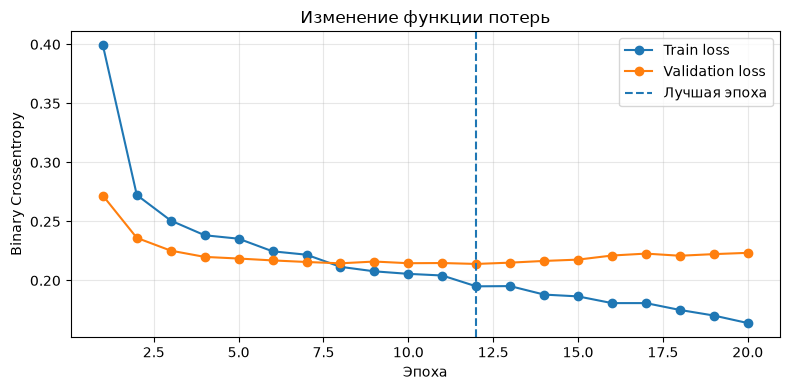

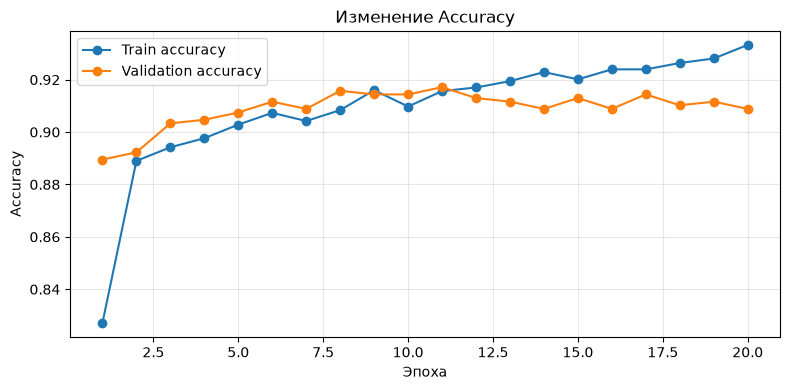

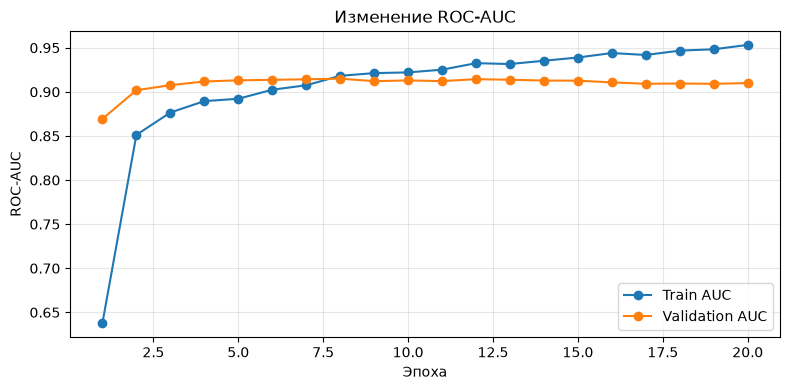

In [142]:

# Определяем эпоху с минимальной ошибкой на валидационной выборке
best_epoch = int(np.argmin(history.history["val_loss"]))

print(f"Лучшая эпоха: {best_epoch + 1}")
print(f"Минимальный val_loss: {history.history['val_loss'][best_epoch]:.4f}")
print(f"val_accuracy в лучшую эпоху: {history.history['val_accuracy'][best_epoch]:.4f}")
print(f"val_auc в лучшую эпоху: {history.history['val_auc'][best_epoch]:.4f}")

epochs = range(1, len(history.history["loss"]) + 1)

# График функции потерь
plt.figure(figsize=(8, 4))
plt.plot(epochs, history.history["loss"], marker="o", label="Train loss")
plt.plot(epochs, history.history["val_loss"], marker="o", label="Validation loss")
plt.axvline(best_epoch + 1, linestyle="--", label="Лучшая эпоха")
plt.xlabel("Эпоха")
plt.ylabel("Binary Crossentropy")
plt.title("Изменение функции потерь")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# График Accuracy
plt.figure(figsize=(8, 4))
plt.plot(epochs, history.history["accuracy"], marker="o", label="Train accuracy")
plt.plot(epochs, history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("Изменение Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# График ROC-AUC
plt.figure(figsize=(8, 4))
plt.plot(epochs, history.history["auc"], marker="o", label="Train AUC")
plt.plot(epochs, history.history["val_auc"], marker="o", label="Validation AUC")
plt.xlabel("Эпоха")
plt.ylabel("ROC-AUC")
plt.title("Изменение ROC-AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



#### Вывод по процессу обучения нейронной сети

В ходе обучения минимальное значение функции потерь на валидационной выборке составило 0,2140 и было достигнуто на 12-й эпохе. В этой точке `val_accuracy` составила 0,9130, а `val_auc` — 0,9144.

После 12-й эпохи обучающая ошибка продолжила снижаться, тогда как валидационная перестала улучшаться. Это указывает на признаки переобучения. Механизм EarlyStopping позволил остановить обучение и восстановить веса лучшей эпохи.

Полученные результаты показывают, что нейронная сеть способна выявлять закономерности в данных. Для дальнейшего улучшения качества необходимо исследовать влияние гиперпараметров на процесс обучения.



### 6.4. Исследование гиперпараметров нейронной сети

Для изучения влияния гиперпараметров проведём серию экспериментов, изменяя максимальное количество эпох, размер батча, количество скрытых слоёв и нейронов, а также функцию активации.

В качестве базовой используется сеть с двумя скрытыми слоями на 64 и 32 нейрона, функцией активации ReLU и размером батча 32.

Для каждого эксперимента сохраняются одинаковые обучающая и валидационная выборки. Качество сравнивается по Accuracy, Precision, Recall, F1-score и ROC-AUC. Для контроля переобучения применяется ранняя остановка, а результаты обучения записываются в TensorBoard.


In [143]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Сохраняем базовую модель и историю обучения
nn_experiment_models = {"baseline": nn_model}
nn_experiment_histories = {"baseline": history}

# Меняем по одному основному параметру за эксперимент
nn_experiments = [
    {
        "name": "epochs_10",
        "max_epochs": 10,
        "batch_size": 32,
        "hidden_units": [64, 32],
        "activation": "relu"
    },
    {
        "name": "epochs_20",
        "max_epochs": 20,
        "batch_size": 32,
        "hidden_units": [64, 32],
        "activation": "relu"
    },
    {
        "name": "batch_16",
        "max_epochs": 50,
        "batch_size": 16,
        "hidden_units": [64, 32],
        "activation": "relu"
    },
    {
        "name": "batch_64",
        "max_epochs": 50,
        "batch_size": 64,
        "hidden_units": [64, 32],
        "activation": "relu"
    },
    {
        "name": "architecture_32",
        "max_epochs": 50,
        "batch_size": 32,
        "hidden_units": [32],
        "activation": "relu"
    },
    {
        "name": "architecture_128_64",
        "max_epochs": 50,
        "batch_size": 32,
        "hidden_units": [128, 64],
        "activation": "relu"
    },
    {
        "name": "activation_tanh",
        "max_epochs": 50,
        "batch_size": 32,
        "hidden_units": [64, 32],
        "activation": "tanh"
    }
]

# Папка для журналов экспериментов TensorBoard
tb_root = Path("C:/Users/Public/Documents/Lab2_TensorBoard")
tb_root.mkdir(parents=True, exist_ok=True)

# Сначала оцениваем уже обученную базовую сеть
nn_experiment_rows = []

def evaluate_nn_model(name, model, train_history, config):
    probabilities = model.predict(
        X_val_processed, verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    best_epoch = int(
        np.argmin(train_history.history["val_loss"])
    ) + 1

    return {
        "Эксперимент": name,
        "Макс. эпох": config["max_epochs"],
        "Фактических эпох": len(train_history.history["loss"]),
        "Batch size": config["batch_size"],
        "Скрытые слои": str(config["hidden_units"]),
        "Активация": config["activation"],
        "Лучшая эпоха": best_epoch,
        "Min val_loss": min(train_history.history["val_loss"]),
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    }

baseline_config = {
    "max_epochs": 50,
    "batch_size": 32,
    "hidden_units": [64, 32],
    "activation": "relu"
}

nn_experiment_rows.append(
    evaluate_nn_model(
        "baseline",
        nn_model,
        history,
        baseline_config
    )
)

# Запускаем альтернативные конфигурации
for config in nn_experiments:
    print(f"Обучение эксперимента: {config['name']}")

    tf.keras.utils.set_random_seed(42)

    inputs = tf.keras.layers.Input(
        shape=(X_nn_train_processed.shape[1],)
    )
    x = inputs

    for layer_index, units in enumerate(config["hidden_units"]):
        x = tf.keras.layers.Dense(
            units,
            activation=config["activation"]
        )(x)

        if layer_index == 0:
            x = tf.keras.layers.Dropout(0.2)(x)

    outputs = tf.keras.layers.Dense(
        1, activation="sigmoid"
    )(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    run_dir = tb_root / (
        config["name"] + "_" +
        datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )

    callback_tensorboard = tf.keras.callbacks.TensorBoard(
        log_dir=run_dir.as_posix(),
        histogram_freq=0,
        update_freq="epoch"
    )

    callback_early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )

    experiment_history = model.fit(
        X_nn_train_processed,
        y_nn_train,
        epochs=config["max_epochs"],
        batch_size=config["batch_size"],
        validation_data=(X_val_processed, y_val),
        callbacks=[
            callback_tensorboard,
            callback_early_stopping
        ],
        verbose=0
    )

    nn_experiment_models[config["name"]] = model
    nn_experiment_histories[config["name"]] = experiment_history

    nn_experiment_rows.append(
        evaluate_nn_model(
            config["name"],
            model,
            experiment_history,
            config
        )
    )

    print(
        f"  Эпох выполнено: {len(experiment_history.history['loss'])}; "
        f"лучшая эпоха: "
        f"{np.argmin(experiment_history.history['val_loss']) + 1}"
    )

# Итоговая таблица экспериментов
nn_experiment_results = pd.DataFrame(
    nn_experiment_rows
).set_index("Эксперимент")

display(
    nn_experiment_results.style.format({
        "Min val_loss": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


Обучение эксперимента: epochs_10
  Эпох выполнено: 10; лучшая эпоха: 8
Обучение эксперимента: epochs_20
  Эпох выполнено: 20; лучшая эпоха: 12
Обучение эксперимента: batch_16
  Эпох выполнено: 16; лучшая эпоха: 8
Обучение эксперимента: batch_64
  Эпох выполнено: 32; лучшая эпоха: 24
Обучение эксперимента: architecture_32
  Эпох выполнено: 27; лучшая эпоха: 19
Обучение эксперимента: architecture_128_64
  Эпох выполнено: 16; лучшая эпоха: 8
Обучение эксперимента: activation_tanh
  Эпох выполнено: 33; лучшая эпоха: 25


,Макс. эпох,Фактических эпох,Batch size,Скрытые слои,Активация,Лучшая эпоха,Min val_loss,Accuracy,Precision,Recall,F1,ROC-AUC
Эксперимент,,,,,,,,,,,,
baseline,50,20,32,"[64, 32]",relu,12,0.2140,0.9130,0.6515,0.5181,0.5772,0.9146
epochs_10,10,10,32,"[64, 32]",relu,8,0.2145,0.9157,0.6667,0.5301,0.5906,0.9146
epochs_20,20,20,32,"[64, 32]",relu,12,0.2140,0.9130,0.6515,0.5181,0.5772,0.9146
batch_16,50,16,16,"[64, 32]",relu,8,0.2158,0.9088,0.6164,0.5422,0.5769,0.9146
batch_64,50,32,64,"[64, 32]",relu,24,0.2151,0.9130,0.6429,0.5422,0.5882,0.9142
architecture_32,50,27,32,[32],relu,19,0.2149,0.9047,0.6167,0.4458,0.5175,0.9127
architecture_128_64,50,16,32,"[128, 64]",relu,8,0.2120,0.9088,0.6197,0.5301,0.5714,0.9163
activation_tanh,50,33,32,"[64, 32]",tanh,25,0.2080,0.9033,0.5942,0.4940,0.5395,0.9197



#### Вывод по исследованию гиперпараметров нейронной сети

Наибольший F1-score на валидационной выборке показал эксперимент `epochs_10` — 0,5906. Наибольший ROC-AUC (0,9197) и минимальный `val_loss` (0,2080) получены при использовании функции активации `tanh`.

Уменьшение архитектуры до одного скрытого слоя из 32 нейронов снизило F1-score до 0,5175. Изменение размера батча также повлияло на результаты, однако различия между значениями 16, 32 и 64 оказались небольшими.

Таким образом, влияние гиперпараметров зависит от выбранной метрики. Полученные результаты будут использованы для выбора конфигурации перед итоговой оценкой нейросети на тестовой выборке.


### 6.5. Мониторинг обучения с помощью TensorBoard

Для визуального контроля процесса обучения нейронной сети использован TensorBoard. С его помощью отслеживались изменения Accuracy, ROC-AUC и функции потерь (loss) на обучающей и валидационной выборках, а также сравнивались эксперименты с различными гиперпараметрами.

**Динамика Accuracy и ROC-AUC:**

![Графики Accuracy и ROC-AUC в TensorBoard](tensorboard_metrics.png)

**Динамика функции потерь:**

![График функции потерь в TensorBoard](tensorboard_loss.png)

#### Вывод по TensorBoard

По графикам TensorBoard видно, что в первые эпохи качество модели быстро улучшается: Accuracy и ROC-AUC растут, а функция потерь снижается. Далее темп улучшения уменьшается, а на части экспериментов наблюдается стабилизация или незначительное ухудшение валидационных метрик, что указывает на начало переобучения.

Сравнение запусков показывает, что различные гиперпараметры действительно влияют на динамику обучения. Эксперимент `epochs_10` показал лучший F1-score на валидационной выборке, а `activation_tanh` — лучший ROC-AUC и минимальное значение функции потерь.


## 7. Сравнительный анализ моделей

### 7.1. Итоговая оценка на тестовой выборке

Для итогового сравнения используем тестовую выборку, которая не участвовала в настройке гиперпараметров. Классические модели оцениваются с лучшими параметрами, найденными при кросс-валидации. Для нейронной сети используется конфигурация `epochs_10`, показавшая наибольший F1-score на валидационной выборке.

Качество всех моделей оценивается по Accuracy, Precision, Recall, F1-score и ROC-AUC. Для классификации используется порог вероятности 0,5.


In [144]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Выбираем конфигурацию по результатам валидации
nn_best_name = nn_experiment_results["F1"].idxmax()

nn_best_config = next(
    config for config in nn_experiments
    if config["name"] == nn_best_name
)


# Используем лучшую эпоху по валидационной ошибке
nn_best_history = nn_experiment_histories[nn_best_name]

nn_final_epochs = (
    int(np.argmin(nn_best_history.history["val_loss"])) + 1
)


print("Выбранная конфигурация:", nn_best_name)
print("Эпох для финального обучения:", nn_final_epochs)
print("Размер полной обучающей выборки:", len(X_train))

# 2. Переобучаем предобработку на всей обучающей выборке
nn_preprocessor_final = clone(preprocessor_scaled)

X_train_nn_final = nn_preprocessor_final.fit_transform(X_train)
X_test_nn_final = nn_preprocessor_final.transform(X_test)

# 3. Создаём нейросеть выбранной архитектуры
tf.keras.utils.set_random_seed(42)

inputs = tf.keras.layers.Input(
    shape=(X_train_nn_final.shape[1],)
)

x = inputs

for layer_index, units in enumerate(nn_best_config["hidden_units"]):
    x = tf.keras.layers.Dense(
        units,
        activation=nn_best_config["activation"]
    )(x)

    if layer_index == 0:
        x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

nn_final_model = tf.keras.Model(inputs=inputs, outputs=outputs)

nn_final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

# 4. Обучаем на всех 3616 объектах без использования теста
nn_final_model.fit(
    X_train_nn_final,
    y_train,
    epochs=nn_final_epochs,
    batch_size=nn_best_config["batch_size"],
    verbose=1
)

# 5. Оцениваем классические модели на тестовой выборке
test_results = []
test_scores = {}

for name, search in tuned_searches.items():
    model = search.best_estimator_

    predictions = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)

    test_scores[name] = scores

    test_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

# 6. Оцениваем финальную нейросеть на тестовой выборке
nn_probabilities = nn_final_model.predict(
    X_test_nn_final,
    verbose=0
).ravel()

nn_predictions = (nn_probabilities >= 0.5).astype(int)

test_scores["Neural Network"] = nn_probabilities

test_results.append({
    "Модель": f"Neural Network (финальная, {nn_final_epochs} эпох)",
    "Accuracy": accuracy_score(y_test, nn_predictions),
    "Precision": precision_score(
        y_test, nn_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, nn_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, nn_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, nn_probabilities)
})

# 7. Формируем обновлённую итоговую таблицу
test_results_df = (
    pd.DataFrame(test_results)
    .set_index("Модель")
    .sort_values("F1", ascending=False)
)

display(test_results_df.style.format("{:.4f}"))


Выбранная конфигурация: epochs_10
Эпох для финального обучения: 8
Размер полной обучающей выборки: 3616
Epoch 1/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8415 - auc: 0.6869 - loss: 0.3699
Epoch 2/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8899 - auc: 0.8576 - loss: 0.2644
Epoch 3/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8991 - auc: 0.8871 - loss: 0.2420
Epoch 4/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9043 - auc: 0.8931 - loss: 0.2334
Epoch 5/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9068 - auc: 0.9048 - loss: 0.2239
Epoch 6/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9062 - auc: 0.9063 - loss: 0.2212
Epoch 7/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9107 - auc: 0.9133 - loss: 0.2146
Epoch 8/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9104 - auc: 0.9190 - loss: 0.2112


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
SVM,0.8453,0.4126,0.8173,0.5484,0.9019
LDA,0.8939,0.5556,0.3846,0.4545,0.8905
Decision Tree,0.8829,0.4886,0.4135,0.4479,0.8033
"Neural Network (финальная, 8 эпох)",0.8928,0.5636,0.2981,0.3899,0.9057
BernoulliNB,0.8530,0.3694,0.3942,0.3814,0.7981
GaussianNB,0.8210,0.3092,0.4519,0.3672,0.7881
KNN,0.8862,0.5102,0.2404,0.3268,0.7335
ComplementNB,0.8729,0.4127,0.2500,0.3114,0.7354
MultinomialNB,0.8751,0.4182,0.2212,0.2893,0.7412



#### Вывод по итоговой оценке моделей

На тестовой выборке наибольший F1-score показала модель SVM (0,5484), которая также обеспечила наибольший Recall (0,8173). Нейронная сеть продемонстрировала наибольшие Precision (0,5636) и ROC-AUC (0,9057), а LDA — наибольшую Accuracy (0,8939).

Таким образом, SVM лучше обнаруживает клиентов, оформивших депозит, тогда как нейронная сеть демонстрирует высокую точность положительных предсказаний и способность различать классы. Выбор модели зависит от приоритетной метрики и допустимого количества ошибочных положительных предсказаний.



### 7.2. Сравнение моделей с помощью ROC-кривых

ROC-кривая показывает зависимость доли верно обнаруженных положительных объектов (TPR) от доли ложноположительных предсказаний (FPR) при изменении порога классификации.

Площадь под кривой ROC-AUC используется для сравнения способности моделей различать два класса. Чем выше ROC-AUC, тем лучше модель ранжирует положительные и отрицательные объекты.


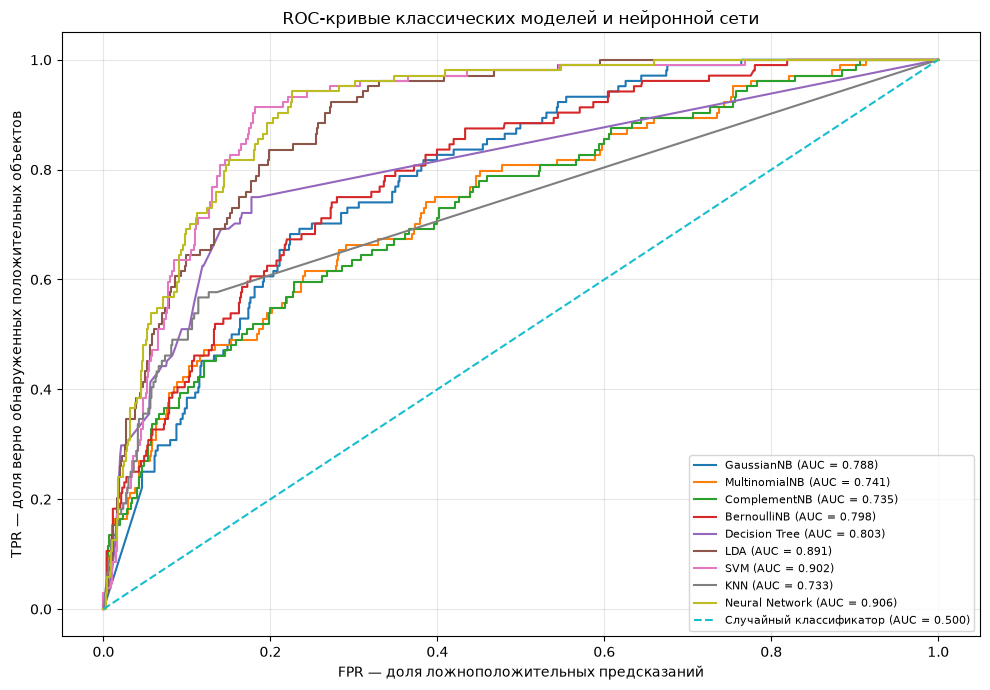

In [145]:

from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(10, 7))

for name, scores in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_value = roc_auc_score(y_test, scores)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

# Случайный классификатор для сравнения
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Случайный классификатор (AUC = 0.500)"
)

plt.xlabel("FPR — доля ложноположительных предсказаний")
plt.ylabel("TPR — доля верно обнаруженных положительных объектов")
plt.title("ROC-кривые классических моделей и нейронной сети")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



#### Вывод по ROC-кривым

Наибольший ROC-AUC на тестовой выборке показала нейронная сеть (0,9057), немного опередив SVM (0,9019) и LDA (0,8905). Наименьшие значения получены у KNN (0,7335) и ComplementNB (0,7354).

Таким образом, нейронная сеть, SVM и LDA лучше остальных рассмотренных моделей различают клиентов, оформивших и не оформивших депозит.



### 7.3. Сравнение моделей по основным метрикам

Для дополнительного сравнения построим столбчатые диаграммы Accuracy, Precision, Recall и F1-score на тестовой выборке. Это позволит оценить общую точность моделей, качество положительных предсказаний, полноту обнаружения клиентов и баланс Precision и Recall.


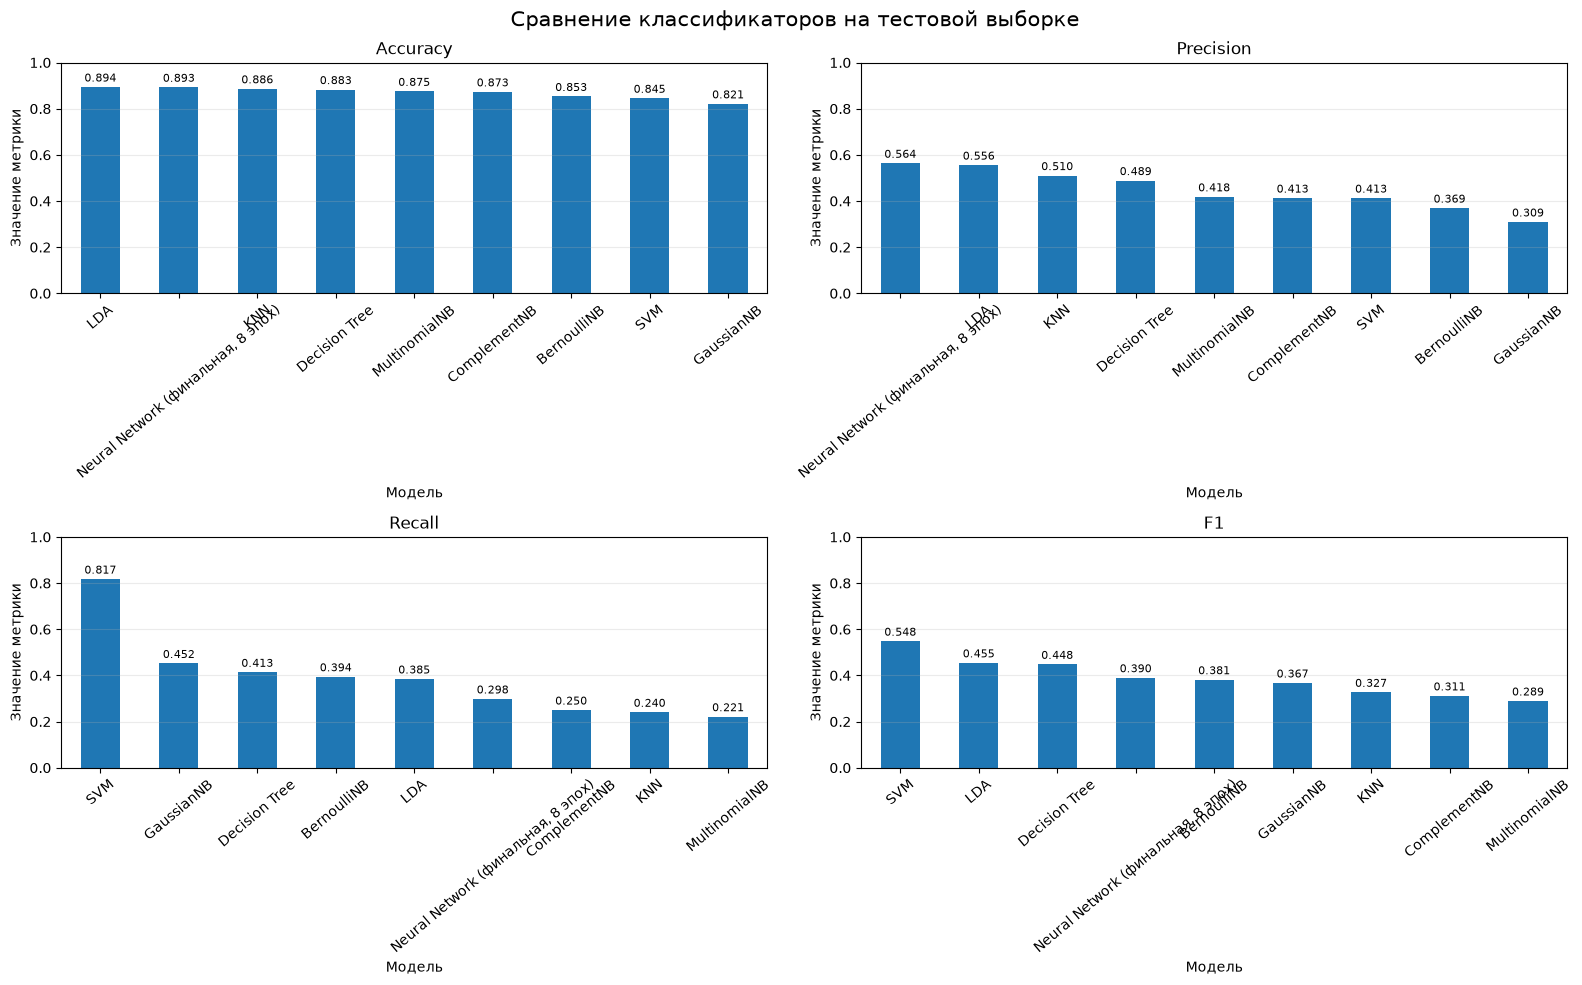

In [146]:

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, metric in zip(axes.flat, metrics_to_plot):
    values = test_results_df[metric].sort_values(ascending=False)

    values.plot(kind="bar", ax=ax)

    ax.set_title(metric)
    ax.set_xlabel("Модель")
    ax.set_ylabel("Значение метрики")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelrotation=40)
    ax.grid(axis="y", alpha=0.25)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)

fig.suptitle(
    "Сравнение классификаторов на тестовой выборке",
    fontsize=15
)

plt.tight_layout()
plt.show()



#### Вывод по сравнению основных метрик

На тестовой выборке LDA показала наибольшую Accuracy (0,8939), нейронная сеть — наибольшую Precision (0,5636), а SVM — наибольшие Recall (0,8173) и F1-score (0,5484).

Таким образом, выбор модели зависит от цели классификации. SVM позволяет обнаружить большую долю клиентов, оформивших депозит, а нейронная сеть демонстрирует высокую Precision и наибольший ROC-AUC. При этом ни одна модель не является лучшей по всем метрикам одновременно.



## 8. Заключение

В ходе лабораторной работы были изучены методы классификации данных и принципы построения нейронных сетей. На датасете Bank Marketing выполнены анализ и предобработка данных, построены восемь классических моделей классификации и нейронная сеть на TensorFlow.

Качество моделей оценивалось по Accuracy, Precision, Recall, F1-score и ROC-AUC. Настройка гиперпараметров позволила улучшить результаты ряда классических классификаторов. Для нейронной сети были исследованы влияние количества эпох, размера батча, архитектуры и функции активации, а процесс обучения визуализирован с помощью TensorBoard.

На тестовой выборке лучший F1-score показала модель SVM (0,5484), а наибольший ROC-AUC — нейронная сеть (0,9057). SVM также обеспечила наибольший Recall (0,8173), тогда как нейронная сеть показала наибольшую Precision (0,5636), а LDA — наибольшую Accuracy (0,8939).

Таким образом, выбор наиболее подходящей модели зависит от задачи. Если приоритетом является обнаружение максимального числа потенциальных клиентов, предпочтительнее SVM. Если важны точность положительных предсказаний и способность различать классы, перспективным вариантом является нейронная сеть.

Цель лабораторной работы достигнута: рассмотрены методы классификации, проведено исследование гиперпараметров, реализована нейронная сеть и выполнено сравнительное оценивание моделей.
